# مرحله دوم: شناخت و بررسی داده‌ها (Data Understanding)

## مقدمه مرحله Data Understanding

### 2. Data Understanding
### شناخت، بررسی ساختار و ارزیابی کیفیت داده‌ها

در این مرحله، دیتاست Online Retail از نظر ساختار، کیفیت، محتوای اطلاعاتی و قابلیت پاسخ‌گویی به اهداف تعریف‌شده در مرحله Business Understanding بررسی می‌شود.

هدف این مرحله شناخت داده‌های تراکنشی و ارزیابی آمادگی آن‌ها برای **بخش‌بندی مشتریان، محاسبه ارزش اقتصادی مشتری، سنجش فرصت بازاریابی و استخراج قوانین انجمنی** است. این مرحله به‌خودی‌خود مدل پیش‌بینی ریزش یا طراحی استراتژی بازاریابی تولید نمی‌کند؛ این فعالیت‌ها خارج از محدوده Data Understanding هستند.

در این مرحله هیچ حذف یا اصلاح نهایی روی داده‌های اصلی انجام نمی‌شود. یافته‌ها، محدودیت‌ها و تصمیم‌های پیشنهادی ثبت می‌شوند تا در مرحله Data Preparation اجرا و اعتبارسنجی شوند.


## معرفی منبع داده (Data Source)

### 2.1. Dataset Source

داده‌های مورد استفاده در این پروژه از مجموعه داده Online Retail متعلق به مخزن UCI Machine Learning Repository دریافت شده‌اند.

این مجموعه داده شامل سوابق تراکنش‌های یک فروشگاه آنلاین بین‌المللی مستقر در بریتانیا است که در زمینه فروش محصولات هدیه و کالاهای مناسب مناسبت‌های مختلف فعالیت می‌کند.

بازه زمانی ثبت تراکنش‌ها از 1 دسامبر 2010 تا 9 دسامبر 2011 است.

بخش قابل‌توجهی از مشتریان این فروشگاه را عمده‌فروشان تشکیل می‌دهند؛ بنابراین رفتار خرید مشتریان ممکن است از نظر تعداد کالا، ارزش سفارش و تناوب خرید با یکدیگر تفاوت زیادی داشته باشد.

ویژگی‌های اصلی دیتاست:

- تعداد رکوردها: 541,909
- تعداد ستون‌ها: 8
- نوع داده: تراکنشی، چندمتغیره و دارای ساختار زمانی
- حوزه کاربرد: تجارت الکترونیک و تحلیل فروش
- واحد پول قیمت‌ها: پوند استرلینگ (GBP)
- شناسه مشتری: CustomerID
- شناسه فاکتور: InvoiceNo
- شناسه محصول: StockCode

این دیتاست شامل اطلاعات مربوط به سفارش‌ها، محصولات، تعداد کالا، قیمت واحد، زمان ثبت تراکنش، مشتری و کشور محل سکونت مشتری است.

منبع رسمی:
https://archive.ics.uci.edu/dataset/352/online+retail

Citation:
Chen, D. (2015). Online Retail [Dataset]. UCI Machine Learning Repository.
DOI: 10.24432/C5BW33

## شناخت متغیر ها و نقش انها در  پروژه (Data Features)

## 2.2. Dataset Features and Business Relevance

دیتاست Online Retail شامل هشت متغیر اصلی است که هرکدام اطلاعات متفاوتی درباره تراکنش، محصول، مشتری و زمان خرید ارائه می‌کنند.

شناخت نقش هر متغیر برای تعیین کاربرد آن در مراحل بعدی داده‌کاوی ضروری است.

| نام ستون | نوع مفهومی | شرح | کاربرد در پروژه |
|---|---|---|---|
| InvoiceNo | شناسه فاکتور | شماره یکتای فاکتور یا تراکنش | تشخیص سفارش‌ها، لغوها و تشکیل سبد خرید |
| StockCode | شناسه محصول | کد اختصاصی هر محصول | شناسایی محصولات و استخراج قوانین انجمنی |
| Description | متنی / دسته‌ای | نام یا توضیح محصول | تفسیر محصولات و بررسی کیفیت اطلاعات محصول |
| Quantity | عدد صحیح | تعداد کالا در هر ردیف تراکنش | محاسبه تعداد خرید و بررسی مرجوعی |
| InvoiceDate | زمانی | تاریخ و ساعت ثبت تراکنش | تحلیل رفتار زمانی، Recency و روند خرید |
| UnitPrice | عددی پیوسته | قیمت هر واحد محصول بر حسب پوند | محاسبه ارزش تراکنش و ارزش اقتصادی |
| CustomerID | شناسه مشتری | شناسه اختصاصی مشتری | تجمیع تراکنش‌ها و ساخت پروفایل مشتری |
| Country | دسته‌ای | کشور محل سکونت مشتری | تحلیل جغرافیایی رفتار خرید |

### بررسی اهمیت هر متغیر

1. InvoiceNo:
   برای شناسایی سفارش‌های مستقل، شمارش تعداد فاکتورها و تشکیل سبد خرید مورد استفاده قرار می‌گیرد. وجود حرف C در ابتدای برخی شماره‌ها نشان‌دهنده فاکتور لغوشده است.

2. StockCode:
   شناسه اصلی محصول است و در تحلیل تنوع محصولات، محاسبه Product Diversity و استخراج قوانین انجمنی اهمیت دارد.

3. Description:
   اطلاعات متنی محصول را ارائه می‌کند. این ستون برای تفسیر نتایج و بررسی ارتباط نام محصولات با کد آن‌ها مفید است.

4. Quantity:
   تعداد کالاهای ثبت‌شده در هر ردیف تراکنش را نشان می‌دهد. مقادیر منفی می‌توانند با مرجوعی یا اصلاح تراکنش ارتباط داشته باشند.

5. InvoiceDate:
   یکی از مهم‌ترین متغیرهای پروژه است؛ زیرا امکان بررسی ترتیب زمانی خریدها، آخرین خرید، فاصله بین سفارش‌ها و تغییر رفتار مشتری را فراهم می‌کند.

6. UnitPrice:
   قیمت واحد محصول را مشخص می‌کند و همراه Quantity برای محاسبه ارزش ناخالص و خالص تراکنش به کار می‌رود.

7. CustomerID:
   کلید اصلی تشکیل مجموعه داده در سطح مشتری است. رکوردهای فاقد این شناسه امکان انتساب مطمئن به یک مشتری مشخص را ندارند.

8. Country:
   امکان بررسی تفاوت‌های جغرافیایی در رفتار خرید و ارزش تراکنش مشتریان را فراهم می‌کند.

### ارتباط متغیرها با اهداف اصلی پروژه

- Clustering: CustomerID، InvoiceNo، InvoiceDate، Quantity، UnitPrice و StockCode.
- Customer Value Score: Quantity، UnitPrice، InvoiceNo و CustomerID.
- Marketing Opportunity Score: CustomerID، InvoiceDate، InvoiceNo و شاخص‌های ارزش خرید.
- Association Rule Mining: InvoiceNo و StockCode.
- Country Analysis: Country و شاخص‌های رفتاری و اقتصادی.

### بررسی اولیه قابلیت استفاده از متغیرها

پیش از اجرای تحلیل‌های اصلی باید مشخص شود که هر ستون از نظر نوع داده، کامل‌بودن اطلاعات، یکتایی و سازگاری با سایر متغیرها در چه وضعیتی قرار دارد.

همچنین باید توجه داشت که شناسه‌هایی مانند CustomerID، InvoiceNo و StockCode اگرچه به‌صورت عددی ذخیره شده باشند، متغیرهای عددی پیوسته نیستند و نباید مستقیماً به‌عنوان ویژگی عددی در محاسبه فاصله خوشه‌بندی استفاده شوند.

برای مثال، اختلاف عددی بین CustomerID برابر 12345 و 12346 هیچ مفهوم رفتاری یا اقتصادی ندارد.

این شناسه‌ها برای اتصال، گروه‌بندی و شناسایی موجودیت‌ها استفاده می‌شوند؛ نه برای اندازه‌گیری فاصله عددی.

## بارگذاری و بررسی اولیه داده ها (Initial Data Loading)

### 2.3. Initial Data Loading

در این بخش، فایل خام Online Retail بارگذاری می‌شود و یک نسخه مستقل از داده‌ها برای انجام بررسی‌های اکتشافی ایجاد خواهد شد.

از آنجا که هدف این مرحله ممیزی و شناخت داده‌هاست، نسخه اولیه دیتاست باید بدون تغییر حفظ شود.

برای جلوگیری از تغییر ناخواسته اطلاعات اصلی، تمام بررسی‌ها و محاسبات کمکی روی نسخه جداگانه‌ای انجام خواهند شد.

در این مرحله موارد زیر بررسی می‌شوند:

- موفقیت بارگذاری فایل.
- تعداد رکوردها و ستون‌ها.
- نمایش نمونه‌ای از داده‌ها.
- بررسی اولیه ساختار اطلاعات.
- اطمینان از حفظ نسخه خام.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("../Online Retail.csv")

audit_df = df.copy(deep=True)

print("Dataset loaded successfully.")

print("Dataset Shape:", audit_df.shape)

display(audit_df.head())

display(audit_df.tail())

Dataset loaded successfully.
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France


### تفسیر خروجی بارگذاری

دیتاست با موفقیت بارگذاری شده و ابعاد آن **541,909 ردیف و 8 ستون** است؛ بنابراین با ساختار مورد انتظار Online Retail سازگار است. نمونه ابتدا و انتهای داده‌ها نیز ستون‌های شناسه فاکتور، محصول، تعداد، تاریخ، قیمت، مشتری و کشور را نشان می‌دهد.

InvoiceDate از همان زمان بارگذاری به datetime تبدیل شده است تا مقایسه تاریخ‌ها و تحلیل زمانی روی رشته انجام نشود. هر ردیف نماینده قلم کالا در فاکتور است، نه مشتری یا سفارش مستقل.

## بررسی ابعاد دیتاست (Dataset Dimensions)

### 2.4. Dataset Dimensions

در این بخش، ابعاد دیتاست از نظر تعداد ردیف‌ها و ستون‌ها بررسی می‌شود.

تعداد ردیف‌ها نشان‌دهنده حجم رکوردهای تراکنشی و تعداد ستون‌ها نشان‌دهنده تعداد متغیرهای ثبت‌شده برای هر رکورد است.

بررسی ابعاد داده برای ارزیابی حجم اطلاعات، تعیین هزینه پردازش و برنامه‌ریزی مراحل بعدی ضروری است.

همچنین باید توجه داشت که هر ردیف الزاماً معادل یک سفارش مستقل یا یک مشتری نیست؛ بلکه یک ردیف می‌تواند نماینده یک قلم کالا در یک فاکتور باشد.

In [7]:
rows, columns = audit_df.shape

print(f"Number of Rows: {rows:,}")
print(f"Number of Columns: {columns}")
print(f"Total Cells: {rows * columns:,}")
print(f"Memory Usage: {audit_df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

Number of Rows: 541,909
Number of Columns: 8
Total Cells: 4,335,272
Memory Usage: 173.12 MB


### تفسیر خروجی

تعداد ردیف‌ها حجم اطلاعات تراکنشی موجود را مشخص می‌کند؛ اما برای تحلیل رفتار مشتریان باید این اطلاعات در مراحل بعدی به سطح مشتری و سفارش تبدیل شوند.

برای مثال:

- تعداد ردیف‌ها برابر با تعداد مشتریان نیست.
- تعداد ردیف‌ها برابر با تعداد فاکتورها نیست.
- یک فاکتور می‌تواند شامل چندین محصول و چندین ردیف باشد.
- یک مشتری می‌تواند در طول دوره زمانی چندین فاکتور ثبت کرده باشد.

بنابراین در مراحل بعدی باید سه سطح داده از یکدیگر تفکیک شوند:

1. Transaction-Level: سطح ردیف تراکنش.
2. Invoice-Level: سطح فاکتور یا سفارش.
3. Customer-Level: سطح مشتری.

این تفکیک برای جلوگیری از محاسبات اشتباه در Frequency، AOV، Monetary و سایر ویژگی‌ها ضروری است.

## بررسی ساختار و نوع داده ستون ها (Data Type and Structure)

### 2.5. Data Types and Structure

در این بخش، نوع داده هر ستون و میزان کامل‌بودن اطلاعات آن بررسی می‌شود.

هدف، اطمینان از سازگاری نوع داده‌ها با ماهیت واقعی متغیرهاست.

برای مثال:

- InvoiceDate باید از نوع زمانی باشد.
- Quantity باید عددی صحیح باشد.
- UnitPrice باید عددی پیوسته باشد.
- شناسه‌های CustomerID، InvoiceNo و StockCode باید از نظر مفهومی دسته‌ای یا شناسه‌ای در نظر گرفته شوند.
- Country و Description باید متغیرهای دسته‌ای یا متنی باشند.

همچنین باید بررسی شود که آیا داده‌ها دارای مقادیر Null هستند یا خیر و آیا نوع ذخیره‌سازی فعلی امکان انجام محاسبات مورد نیاز را فراهم می‌کند.

In [8]:

audit_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


### بررسی نوع داده هر ستون 

In [9]:

display(
    pd.DataFrame({
        "Column": audit_df.columns,
        "Data Type": audit_df.dtypes.astype(str).values,
        "Non-Null Count": audit_df.notna().sum().values,
        "Null Count": audit_df.isna().sum().values
    })
)

,Column,Data Type,Non-Null Count,Null Count
0,InvoiceNo,str,541909,0
1,StockCode,str,541909,0
2,Description,str,540455,1454
3,Quantity,int64,541909,0
4,InvoiceDate,str,541909,0
5,UnitPrice,float64,541909,0
6,CustomerID,float64,406829,135080
7,Country,str,541909,0


### بررسی سازگاری نوع داده‌ها

در فایل خام، InvoiceDate به‌صورت رشته ذخیره شده بود. در کد بارگذاری، این ستون با قالب `%m/%d/%Y %H:%M` به datetime تبدیل شده است؛ بنابراین محاسبات min/max، مرتب‌سازی زمانی و تجمیع ماهانه روی مقادیر زمانی واقعی انجام می‌شود.

CustomerID و InvoiceNo و StockCode از نظر مفهومی شناسه‌اند، نه متغیرهای پیوسته. Quantity عدد صحیح و UnitPrice عددی پیوسته است. تبدیل‌های تکمیلی شناسه‌ها و سیاست مدیریت مقادیر نامعتبر در Data Preparation مستند خواهد شد.

### ایجاد جدول ارزیابی نوع داده ها 

In [10]:


expected_types = {
    "InvoiceNo": "Categorical / Identifier",
    "StockCode": "Categorical / Identifier",
    "Description": "Text / Categorical",
    "Quantity": "Integer",
    "InvoiceDate": "Datetime",
    "UnitPrice": "Float",
    "CustomerID": "Categorical / Identifier",
    "Country": "Categorical"
}

type_audit = pd.DataFrame({
    "Column": audit_df.columns,
    "Current Type": audit_df.dtypes.astype(str).values,
    "Expected Conceptual Type": [
        expected_types[col] for col in audit_df.columns
    ]
})

display(type_audit)

,Column,Current Type,Expected Conceptual Type
0,InvoiceNo,str,Categorical / Identifier
1,StockCode,str,Categorical / Identifier
2,Description,str,Text / Categorical
3,Quantity,int64,Integer
4,InvoiceDate,str,Datetime
5,UnitPrice,float64,Float
6,CustomerID,float64,Categorical / Identifier
7,Country,str,Categorical


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Online Retail.csv")

# نسخه ممیزی مستقل؛ تاریخ از همان زمان بارگذاری به datetime تبدیل می‌شود.
audit_df = df.copy(deep=True)
audit_df["InvoiceDate"] = pd.to_datetime(
    audit_df["InvoiceDate"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

print("Dataset loaded successfully.")
print("Dataset Shape:", audit_df.shape)
print("InvoiceDate dtype:", audit_df["InvoiceDate"].dtype)

display(audit_df.head())
display(audit_df.tail())

In [11]:

total_rows = len(audit_df)

missing_count = audit_df.isna().sum()

missing_percentage = (missing_count / total_rows) * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage,
    "Non-Missing Count": audit_df.notna().sum()
})

missing_report = missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_report)

,Missing Count,Missing Percentage,Non-Missing Count
CustomerID,135080,24.926694,406829
Description,1454,0.268311,540455
StockCode,0,0.000000,541909
InvoiceNo,0,0.000000,541909
Quantity,0,0.000000,541909
InvoiceDate,0,0.000000,541909
UnitPrice,0,0.000000,541909
Country,0,0.000000,541909


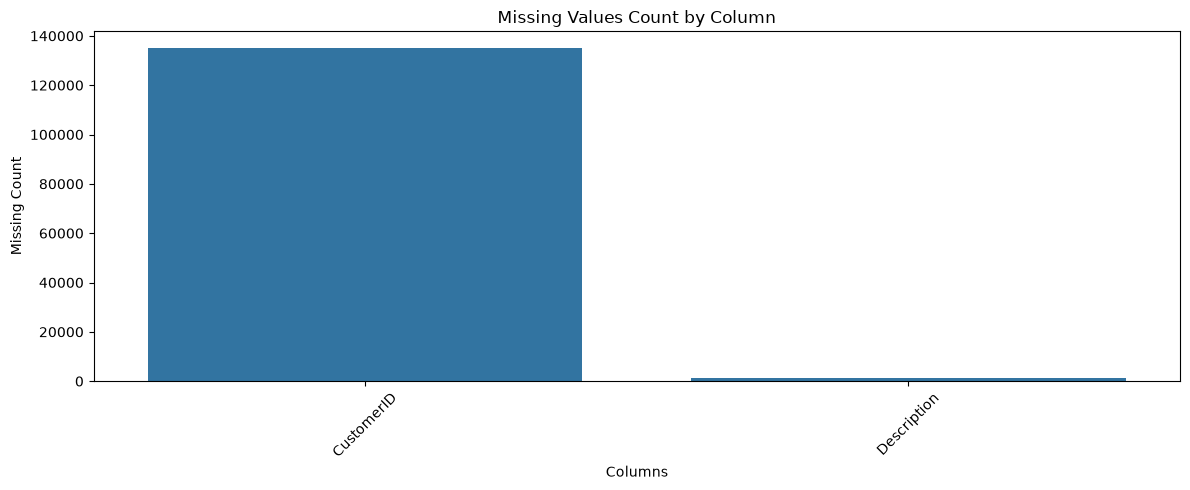

In [12]:


missing_values = missing_report[
    missing_report["Missing Count"] > 0
]

plt.figure(figsize=(12, 5))

sns.barplot(
    x=missing_values.index,
    y=missing_values["Missing Count"]
)

plt.title("Missing Values Count by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:


missing_patterns = (
    audit_df.isna()
    .value_counts()
    .reset_index(name="Record Count")
)

missing_patterns["Percentage"] = (
    missing_patterns["Record Count"] / len(audit_df) * 100
)

display(missing_patterns.head(20))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Record Count,Percentage
0,False,False,False,False,False,False,False,False,406829,75.073306
1,False,False,False,False,False,False,True,False,133626,24.658384
2,False,False,True,False,False,False,True,False,1454,0.268311


### بررسی تخصصی مقادیر گمشده

پس از شناسایی ستون‌های دارای مقادیر گمشده، باید منشأ و پیامد آن‌ها بررسی شود.

#### 1. Missing CustomerID

مهم‌ترین مسئله این ستون، عدم امکان شناسایی مشتری مربوط به برخی تراکنش‌هاست.

تأثیر بر پروژه:

- Customer Segmentation: مانع انتساب این رکوردها به یک خوشه مشتری مشخص می‌شود.
- Customer Value Score: مانع محاسبه ارزش اقتصادی برای مشتری ناشناس می‌شود.
- Marketing Opportunity Score: امکان محاسبه شاخص فرصت برای مشتری ناشناس وجود ندارد.
- Customer Prioritization: این رکوردها نمی‌توانند مستقیماً در فهرست مشتریان منتخب قرار بگیرند.
- Association Rules: در صورت معتبر بودن InvoiceNo و StockCode، ممکن است همچنان قابل استفاده باشند.

#### 2. Missing Description

تأثیر بر پروژه:

- تفسیر نام محصولات را دشوار می‌کند.
- ممکن است در گزارش‌های محصولی ابهام ایجاد کند.
- در صورت معتبر بودن StockCode، الزاماً مانع استخراج قوانین انجمنی نیست.

#### 3. بررسی ارتباط مقادیر گمشده با سایر متغیرها

باید مشخص شود آیا مقادیر گمشده به‌صورت تصادفی در داده‌ها پراکنده شده‌اند یا در الگوی خاصی مانند کشور، تاریخ، نوع فاکتور یا قیمت متمرکز هستند.

نتیجه این بررسی در تصمیم‌گیری مرحله Data Preparation مؤثر خواهد بود.

### بررسی مقادیر گمشده CustomerID در کشور های مختلف و پیدا کردن درصد گمشدگی

In [14]:


if "CustomerID" in audit_df.columns:

    missing_customer_by_country = (
        audit_df.assign(
            MissingCustomerID=audit_df["CustomerID"].isna()
        )
        .groupby("Country")
        .agg(
            TotalRecords=("MissingCustomerID", "size"),
            MissingCustomerRecords=("MissingCustomerID", "sum")
        )
    )

    missing_customer_by_country["Missing Percentage"] = (
        missing_customer_by_country["MissingCustomerRecords"]
        / missing_customer_by_country["TotalRecords"] * 100
    )

    display(
        missing_customer_by_country.sort_values(
            "Missing Percentage",
            ascending=False
        )
    )

,TotalRecords,MissingCustomerRecords,Missing Percentage
Country,,,
Hong Kong,288,288,100.000000
Unspecified,446,202,45.291480
United Kingdom,495478,133600,26.963861
Israel,297,47,15.824916
Bahrain,19,2,10.526316
EIRE,8196,711,8.674963
Switzerland,2002,125,6.243756
Portugal,1519,39,2.567479
France,8557,66,0.771298


### بررسی مقادیر گمشده CustomerID در ماه های مختلف

In [15]:
temp_missing = audit_df.copy()

temp_missing["InvoiceDate"] = pd.to_datetime(
    temp_missing["InvoiceDate"],
    errors="coerce"
)

temp_missing["Month"] = (
    temp_missing["InvoiceDate"].dt.to_period("M")
)

missing_by_month = (
    temp_missing.groupby("Month")
    .agg(
        TotalRecords=("CustomerID", "size"),
        MissingCustomerID=("CustomerID", lambda x: x.isna().sum())
    )
)

missing_by_month["Missing Percentage"] = (
    missing_by_month["MissingCustomerID"]
    / missing_by_month["TotalRecords"] * 100
)

display(missing_by_month)

,TotalRecords,MissingCustomerID,Missing Percentage
Month,,,
2010-12,42481,15631,36.795273
2011-01,35147,13235,37.656130
2011-02,27707,7344,26.505937
2011-03,36748,8926,24.289757
2011-04,29916,6718,22.456211
2011-05,37030,8122,21.933567
2011-06,36874,9038,24.510495
2011-07,39518,12016,30.406397
2011-08,35284,7622,21.601859


### نتیجه‌گیری مقادیر گمشده

CustomerID در **135,080 ردیف (حدود 24.93٪)** گمشده است و Description در **1,454 ردیف (حدود 0.27٪)** مقدار گمشده دارد. بررسی تفکیکی کشور و ماه نشان می‌دهد الگوی گمشدگی یکنواخت نیست؛ برای نمونه Hong Kong دارای 100٪ گمشدگی CustomerID و گروه Unspecified حدود 45٪ گمشدگی دارد.

**اثر بر اهداف:**
- رکورد فاقد CustomerID برای Segmentation، Customer Value و اولویت‌بندی مشتری قابل انتساب نیست.
- همین رکوردها در صورت داشتن InvoiceNo و StockCode معتبر می‌توانند در ARM استفاده شوند.
- Description گمشده الزاماً مانع ARM نیست، زیرا StockCode شناسه محصول است.

**تصمیم برای Data Preparation:** CustomerID گمشده با شناسه ساختگی پر نشود؛ مجموعه مشتریان و مجموعه فاکتورهای قابل استفاده برای ARM جدا تعریف شوند. Description فقط در صورت نیاز تفسیری با نگاشت معتبر تکمیل شود.

## بررسی شناسه های مشتری ، فاکتور و محصول

### 2.7. Identifier Analysis

در این بخش، شناسه‌های اصلی دیتاست از نظر یکتایی، تعداد مقادیر متمایز، مقادیر گمشده و سازگاری بررسی می‌شوند.

سه شناسه اصلی عبارت‌اند از:

1. CustomerID
2. InvoiceNo
3. StockCode

این شناسه‌ها پایه اصلی تبدیل داده‌های تراکنشی به اطلاعات قابل تحلیل در سطح سفارش، مشتری و محصول هستند.

#### CustomerID

هدف:
بررسی تعداد مشتریان قابل شناسایی و ارزیابی امکان تشکیل پروفایل مشتریان.

#### InvoiceNo

هدف:
بررسی تعداد فاکتورهای مستقل و شناسایی ساختار سفارش‌ها.

#### StockCode

هدف:
بررسی تعداد محصولات متمایز و ارزیابی امکان تحلیل تنوع محصولات و قوانین انجمنی.


In [16]:
identifier_columns = ["CustomerID", "InvoiceNo", "StockCode"]

identifier_report = pd.DataFrame({
    "Column": identifier_columns,
    "Unique Values": [audit_df[col].nunique(dropna=True) for col in identifier_columns],
    "Missing Values": [audit_df[col].isna().sum() for col in identifier_columns],
    "Interpretation": [
        "شناسه مشتری؛ تکرار مقدار در چند ردیف طبیعی است",
        "شناسه فاکتور؛ تکرار مقدار در ردیف‌های اقلام یک فاکتور طبیعی است",
        "شناسه محصول؛ تکرار مقدار در تراکنش‌های مختلف طبیعی است"
    ]
})
display(identifier_report)

print("تکرار مقدار شناسه‌ها، Duplicate Record محسوب نمی‌شود؛ تکراری بودن باید در سطح کل ردیف یا کلید تجاری بررسی شود.")

,Column,Unique Values,Missing Values,Interpretation
0,CustomerID,4372,135080,شناسه مشتری؛ تکرار مقدار در چند ردیف طبیعی است
1,InvoiceNo,25900,0,شناسه فاکتور؛ تکرار مقدار در ردیف‌های اقلام یک...
2,StockCode,4070,0,شناسه محصول؛ تکرار مقدار در تراکنش‌های مختلف ط...


تکرار مقدار شناسه‌ها، Duplicate Record محسوب نمی‌شود؛ تکراری بودن باید در سطح کل ردیف یا کلید تجاری بررسی شود.


### تفسیر شناسه‌ها

InvoiceNo در چندین ردیف تکرار می‌شود، زیرا هر فاکتور می‌تواند شامل چند قلم کالا باشد؛ StockCode نیز در فاکتورهای متعدد تکرار می‌شود. این تکرارها طبیعی‌اند و به‌تنهایی Duplicate Record نیستند.

تعداد شناسه‌های مشتری قابل شناسایی برای تحلیل مشتری کافی است؛ با این حال، CustomerID گمشده باعث می‌شود همه فاکتورها به پروفایل مشتری متصل نباشند. همچنین برخی StockCodeها کدهای غیرمحصولی یا خدماتی هستند و باید پیش از ARM از کدهای محصول قابل فروش تفکیک شوند.

**تصمیم برای Data Preparation:** شناسه‌ها صرفاً برای اتصال و گروه‌بندی استفاده شوند؛ قالب کد محصول و معنای تجاری آن با Description و فهرست کدهای خاص بررسی شود.

In [17]:


invoice_line_counts = (
    audit_df.groupby("InvoiceNo")
    .size()
    .sort_values(ascending=False)
)

display(invoice_line_counts.describe())


display(invoice_line_counts.head(10))

count    25900.000000
mean        20.923127
std         43.031334
min          1.000000
25%          2.000000
50%         10.000000
75%         23.000000
max       1114.000000
dtype: float64

InvoiceNo
573585    1114
581219     749
581492     731
580729     721
558475     705
579777     687
581217     676
537434     675
580730     662
538071     652
dtype: int64

In [18]:


customer_invoice_counts = (
    audit_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

display(customer_invoice_counts.describe())

display(customer_invoice_counts.head(10))

count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64

CustomerID
14911.0    248
12748.0    224
17841.0    169
14606.0    128
15311.0    118
13089.0    118
12971.0     89
14527.0     86
13408.0     81
14646.0     77
Name: InvoiceNo, dtype: int64

In [19]:


product_frequency = (
    audit_df.groupby("StockCode")
    .size()
    .sort_values(ascending=False)
)

display(product_frequency.describe())

display(product_frequency.head(15))

count    4070.000000
mean      133.147174
std       199.903331
min         1.000000
25%        14.000000
50%        62.000000
75%       167.000000
max      2313.000000
dtype: float64

StockCode
85123A    2313
22423     2203
85099B    2159
47566     1727
20725     1639
84879     1502
22720     1477
22197     1476
21212     1385
20727     1350
22383     1348
22457     1280
23203     1267
POST      1256
22386     1251
dtype: int64

### بررسی اعتبار شناسه محصولات

در دیتاست Online Retail، StockCode شناسه اصلی محصول است؛ اما نباید فرض کنیم که تمام کدها الزاماً فقط شامل پنج رقم عددی هستند.

برخی کدها ممکن است شامل حروف باشند یا به اقلام خدماتی، هزینه‌های جانبی و موارد خاص اشاره کنند.

بنابراین باید:

1. کدهای محصول دارای قالب عددی را از کدهای ترکیبی و غیرمعمول تفکیک کنیم.
2. تعداد هر گروه را بررسی کنیم.
3. توضیحات محصولات مربوط به کدهای غیرمعمول را مشاهده کنیم.
4. مشخص کنیم کدام کدها واقعاً معرف محصول قابل فروش هستند.
5. در مرحله Data Preparation درباره استفاده از این کدها در قوانین انجمنی تصمیم بگیریم.

وجود یک کد غیرعددی به‌تنهایی دلیل نامعتبر بودن آن نیست.

In [20]:
stock_codes = (
    audit_df["StockCode"]
    .dropna()
    .astype("string")
    .str.strip()
)

product_code_analysis = pd.Series({
    "Numeric Only": stock_codes.str.fullmatch(r"\d+").sum(),
    "Contains Letters": stock_codes.str.contains(
        r"[A-Za-z]", regex=True
    ).sum(),
    "Contains Special Characters": stock_codes.str.contains(
        r"[^A-Za-z0-9]", regex=True
    ).sum(),
    "Total Non-Missing Codes": stock_codes.size
})

display(product_code_analysis)

Numeric Only                   487036
Contains Letters                54873
Contains Special Characters        71
Total Non-Missing Codes        541909
dtype: int64

## بررسی رکورد های تکراری (Duplicate Records Analysis)

### 2.8. Duplicate Records Analysis

در این بخش، رکوردهای تکراری بررسی می‌شوند تا مشخص شود چه تعداد از اطلاعات ثبت‌شده کاملاً مشابه یا از نظر تجاری تکراری هستند.

وجود رکوردهای تکراری می‌تواند موجب افزایش غیرواقعی تعداد کالاها، ارزش تراکنش‌ها و شاخص‌های رفتاری مشتریان شود.

در این پروژه باید بین دو مفهوم تفاوت قائل شویم:

#### 1. Exact Duplicates

رکوردهایی که تمام مقادیر ستون‌های آن‌ها با یکدیگر یکسان هستند.

#### 2. Business-Level Duplicates

رکوردهایی که از نظر ترکیب شناسه مشتری، فاکتور، محصول، تاریخ، تعداد و قیمت مشابه هستند.

ممکن است دو رکورد کاملاً مشابه در فایل ثبت شده باشند؛ اما بدون بررسی زمینه تجاری نمی‌توان با قطعیت تعیین کرد که یکی از آن‌ها اشتباه است.

همچنین تکرار CustomerID، InvoiceNo یا StockCode به‌تنهایی تکرار رکورد محسوب نمی‌شود.

In [21]:
exact_duplicate_count = audit_df.duplicated().sum()

exact_duplicate_percentage = (
    exact_duplicate_count / len(audit_df) * 100
)

print("Exact Duplicate Records:", exact_duplicate_count)
print("Duplicate Percentage:", exact_duplicate_percentage)

Exact Duplicate Records: 5268
Duplicate Percentage: 0.9721189350979592


**با این قطعه کد مشخص میکنیم کدام ردیف های دیتا فریم تکراری هستند در اینجا پارامتر keep = False یعنی تمام ردیف های تکراری مشخص شوند و در نهایت رکورد هایی ک true شده است در متغییر exact_duplicates ذخیره شوند **

In [22]:
exact_duplicates = audit_df[
    audit_df.duplicated(keep=False)
].sort_values(by=["InvoiceNo", "StockCode"])

display(exact_duplicates.head(30))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,12/1/2010 11:49,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,12/1/2010 11:49,1.65,17920.0,United Kingdom


**اینجا بهتر است تفاوت این کذ وکذ قبلی را بررسی کنیم**
**در کد قبلی ما بررسی کردیم ایا دو ردیف تمام مقادیرشان باهم برابر هست یا خیر ولی در این کد فقط از نظر اطلاعات اصلی یک تراکنش تکراری هستند یا خیر**

In [23]:
business_key = [
    "InvoiceNo",
    "StockCode",
    "CustomerID",
    "InvoiceDate",
    "Quantity",
    "UnitPrice"
]

business_duplicates = audit_df[
    audit_df.duplicated(
        subset=business_key,
        keep=False
    )
]

print("Business-Level Duplicate Records:", len(business_duplicates))

display(business_duplicates.head(30))

Business-Level Duplicate Records: 10151


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom


### بررسی تأثیر رکوردهای تکراری بر پروژه

ممیزی رکوردهای کامل، **5,268 ردیف تکراری** را نشان می‌دهد که **5,192 ردیف** آن‌ها دارای CustomerID هستند. این ردیف‌ها می‌توانند جمع Quantity و Monetary را افزایش دهند.

در مقابل، اگر Frequency بر اساس تعداد InvoiceNo یکتا و ARM بر اساس مجموعه یکتای StockCode در هر Invoice ساخته شود، تکرار یک ردیف در همان فاکتور معمولاً تعداد فاکتورها یا حضور محصول در سبد را افزایش نمی‌دهد.

**تصمیم برای Data Preparation:** تکراری‌ها باید پیش از تجمیع Monetary و Quantity ممیزی شوند؛ حذف آن‌ها بدون بررسی کلید فاکتور-زمان و اثر مالی انجام نشود.

## بررسی فاکتور های لغو شده (Cancellation Analysis)

### 2.9. Cancellation Analysis

در دیتاست Online Retail، شماره فاکتورهایی که با حرف C شروع می‌شوند، نشان‌دهنده فاکتورهای لغوشده هستند.

این ویژگی یکی از مهم‌ترین نشانه‌های موجود برای شناسایی لغو سفارش در داده‌هاست.

با توجه به اهداف پروژه، بررسی فاکتورهای لغوشده اهمیت زیادی دارد؛ زیرا نباید این فاکتورها بدون بررسی وارد محاسبه شاخص‌های خرید مشتری شوند.

در این بخش موارد زیر بررسی می‌شوند:

1. تعداد ردیف‌های دارای شماره فاکتور با پیشوند C.
2. تعداد فاکتورهای لغوشده متمایز.
3. درصد فاکتورهای لغوشده نسبت به کل فاکتورها.
4. تعداد مشتریان مرتبط با فاکتورهای لغوشده.
5. توزیع مقادیر Quantity در فاکتورهای لغوشده.
6. توزیع UnitPrice در فاکتورهای لغوشده.
7. بررسی ارتباط فاکتورهای لغوشده با مقادیر منفی Quantity.
8. بررسی توزیع زمانی لغو سفارش‌ها.

نکته مهم:

لغو سفارش با مرجوعی کالا یکسان نیست. فاکتور دارای پیشوند C نشانه لغو است، اما تشخیص دقیق رابطه میان فاکتور اصلی و فاکتور لغو به بررسی شناسه‌ها، تاریخ‌ها و سایر اطلاعات تراکنش نیاز دارد.

In [24]:


audit_df["IsCancellation"] = (
    audit_df["InvoiceNo"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.startswith("C", na=False)
)


cancellation_rows = audit_df["IsCancellation"].sum()


cancellation_invoices = (
    audit_df.loc[audit_df["IsCancellation"], "InvoiceNo"]
    .nunique()
)


total_invoices = audit_df["InvoiceNo"].nunique()

print("Cancellation Rows:", cancellation_rows)
print("Cancelled Invoices:", cancellation_invoices)
print("Total Invoices:", total_invoices)

print(
    "Cancellation Invoice Percentage:",
    cancellation_invoices / total_invoices * 100
)

Cancellation Rows: 9288
Cancelled Invoices: 3836
Total Invoices: 25900
Cancellation Invoice Percentage: 14.810810810810812


In [25]:
cancellation_data = audit_df[
    audit_df["IsCancellation"]
]

display(
    cancellation_data[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice",
         "CustomerID", "Country"]
    ].head(20)
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/2010 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/2010 10:24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,12/1/2010 12:38,4.25,17897.0,United Kingdom


In [26]:
cancellation_quantity_report = (
    audit_df.groupby("IsCancellation")["Quantity"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Min="min",
        Max="max"
    )
)

display(cancellation_quantity_report)

,Count,Mean,Median,Min,Max
IsCancellation,,,,,
False,532621,10.239972,3.0,-9600,80995
True,9288,-29.885228,-2.0,-80995,-1


In [27]:
cancellation_by_country = (
    audit_df.groupby("Country")
    .agg(
        TotalRecords=("InvoiceNo", "size"),
        CancellationRecords=("IsCancellation", "sum")
    )
)

cancellation_by_country["Cancellation Percentage"] = (
    cancellation_by_country["CancellationRecords"]
    / cancellation_by_country["TotalRecords"] * 100
)

display(
    cancellation_by_country.sort_values(
        "Cancellation Percentage",
        ascending=False
    )
)

,TotalRecords,CancellationRecords,Cancellation Percentage
Country,,,
USA,291,112,38.487973
Czech Republic,30,5,16.666667
Malta,127,15,11.811024
Japan,358,37,10.335196
Saudi Arabia,10,1,10.0
Australia,1259,74,5.877681
Italy,803,45,5.603985
Bahrain,19,1,5.263158
Germany,9495,453,4.770932


### بررسی اثر فاکتورهای لغوشده بر اهداف پروژه

فاکتورهای لغوشده ممکن است در محاسبه شاخص‌های رفتاری و اقتصادی مشتریان اختلال ایجاد کنند.

تأثیر احتمالی:

- Frequency: افزایش غیرواقعی تعداد سفارش‌ها در صورت شمارش لغوها به‌عنوان خرید.
- Monetary: تغییر ارزش خرید در صورت ورود مبلغ لغو به محاسبات.
- Total Quantity: تغییر تعداد کالاهای خریداری‌شده.
- Return Rate: احتمال اشتباه‌گرفتن لغو با مرجوعی.
- Association Rules: ایجاد ارتباط‌های غیرواقعی میان محصولاتی که صرفاً در فاکتور لغوشده ثبت شده‌اند.

### تصمیم پیشنهادی

فاکتورهای لغوشده باید از فاکتورهای خرید معتبر تفکیک شوند.

با این حال، اطلاعات آن‌ها باید برای تحلیل لغو سفارش و در صورت امکان محاسبه Cancellation Rate حفظ شود.

تشخیص نهایی فاکتورهای معتبر در مرحله Data Preparation انجام خواهد شد.

## بررسی مقادیر منفی و صفر (Negative and Zero Values Analysis)

### 2.10. Negative and Zero Values Analysis

در این بخش، مقادیر منفی و صفر در ستون‌های Quantity و UnitPrice بررسی می‌شوند.

این بررسی اهمیت زیادی دارد؛ زیرا مقادیر غیرمثبت لزوماً به معنای خطای ثبت داده نیستند و ممکن است به رویدادهای تجاری متفاوتی مانند مرجوعی، لغو سفارش، اصلاح قیمت یا ثبت اطلاعات غیرقابل فروش مربوط باشند.

#### بررسی Quantity

Quantity نشان‌دهنده تعداد کالاهای ثبت‌شده در یک ردیف تراکنش است.

حالت‌های قابل بررسی:

- Quantity > 0: ثبت تعداد مثبت کالا.
- Quantity = 0: ثبت بدون تعداد قابل فروش.
- Quantity < 0: احتمال مرجوعی، برگشت کالا یا اصلاح تراکنش.

#### بررسی UnitPrice

UnitPrice قیمت واحد کالا را نشان می‌دهد.

حالت‌های قابل بررسی:

- UnitPrice > 0: قیمت مثبت.
- UnitPrice = 0: احتمال ثبت کالای رایگان، نمونه، جایزه یا رکورد غیرمالی.
- UnitPrice < 0: احتمال اصلاح مالی، تخفیف یا ثبت غیرعادی.

هیچ‌کدام از این حالت‌ها نباید بدون بررسی حذف شوند.

In [28]:
quantity_report = pd.Series({
    "Negative Quantity": (audit_df["Quantity"] < 0).sum(),
    "Zero Quantity": (audit_df["Quantity"] == 0).sum(),
    "Positive Quantity": (audit_df["Quantity"] > 0).sum(),
    "Missing Quantity": audit_df["Quantity"].isna().sum()
})

display(quantity_report)

Negative Quantity     10624
Zero Quantity             0
Positive Quantity    531285
Missing Quantity          0
dtype: int64

In [29]:
price_report = pd.Series({
    "Negative UnitPrice": (audit_df["UnitPrice"] < 0).sum(),
    "Zero UnitPrice": (audit_df["UnitPrice"] == 0).sum(),
    "Positive UnitPrice": (audit_df["UnitPrice"] > 0).sum(),
    "Missing UnitPrice": audit_df["UnitPrice"].isna().sum()
})

display(price_report)

Negative UnitPrice         2
Zero UnitPrice          2515
Positive UnitPrice    539392
Missing UnitPrice          0
dtype: int64

In [30]:
quantity_price_conditions = [
    (audit_df["Quantity"] > 0) & (audit_df["UnitPrice"] > 0),
    (audit_df["Quantity"] < 0) & (audit_df["UnitPrice"] > 0),
    (audit_df["Quantity"] > 0) & (audit_df["UnitPrice"] == 0),
    (audit_df["Quantity"] < 0) & (audit_df["UnitPrice"] == 0),
    (audit_df["UnitPrice"] < 0),
    (audit_df["Quantity"] == 0)
]

quantity_price_labels = [
    "Positive Quantity and Positive Price",
    "Negative Quantity and Positive Price",
    "Positive Quantity and Zero Price",
    "Negative Quantity and Zero Price",
    "Negative UnitPrice",
    "Zero Quantity"
]

audit_df["QuantityPriceStatus"] = np.select(
    quantity_price_conditions,
    quantity_price_labels,
    default="Other"
)

display(
    audit_df["QuantityPriceStatus"]
    .value_counts()
    .to_frame("Record Count")
)

,Record Count
QuantityPriceStatus,
Positive Quantity and Positive Price,530104
Negative Quantity and Positive Price,9288
Negative Quantity and Zero Price,1336
Positive Quantity and Zero Price,1179
Negative UnitPrice,2


In [31]:
nonpositive_records = audit_df[
    (audit_df["Quantity"] <= 0) |
    (audit_df["UnitPrice"] <= 0)
]

display(
    nonpositive_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice",
         "CustomerID", "Country"]
    ].head(50)
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/2010 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/2010 10:24,1.65,17548.0,United Kingdom
622,536414,22139,NaN,56,12/1/2010 11:52,0.00,NaN,United Kingdom


### تفسیر مقادیر غیرمثبت

برای تشخیص معنای مقادیر غیرمثبت باید آن‌ها را در کنار شماره فاکتور، تاریخ، شناسه مشتری، شناسه محصول و توضیحات کالا بررسی کرد.

برای مثال:

- Quantity منفی همراه با شماره فاکتور دارای پیشوند C می‌تواند با لغو سفارش ارتباط داشته باشد.
- Quantity منفی در فاکتور بدون پیشوند C ممکن است نشان‌دهنده مرجوعی یا اصلاح تراکنش باشد.
- UnitPrice صفر ممکن است نشان‌دهنده کالای رایگان یا یک رکورد غیرمالی باشد.
- UnitPrice منفی نیازمند بررسی ویژه است و نباید به‌صورت خودکار فروش منفی تلقی شود.

### تصمیم پیشنهادی

رکوردهای دارای Quantity یا UnitPrice غیرمثبت باید به‌صورت جداگانه بررسی شوند.

در مرحله Data Preparation، بر اساس شواهد موجود، رکوردها به گروه‌های خرید معتبر، لغو، مرجوعی، اصلاح مالی و موارد نامشخص تقسیم خواهند شد.

حذف همه مقادیر منفی یا صفر بدون بررسی معنای آن‌ها مجاز نیست.

## تفکیک خرید ، لغو و مرجوعی (Purchase , Cancellation and Return Analysis)

### 2.11. Purchase, Cancellation and Return Analysis

یکی از مهم‌ترین چالش‌های دیتاست Online Retail، تفکیک رویدادهای مختلف تجاری است.

وجود فاکتورهای لغوشده و مقادیر منفی باعث می‌شود که نتوان تمام ردیف‌های دیتاست را به‌عنوان خرید واقعی در نظر گرفت.

برای تحلیل صحیح رفتار مشتریان، لازم است میان سه مفهوم تفاوت قائل شویم:

#### 1. Purchase

تراکنشی که نشان‌دهنده خرید کالا توسط مشتری است.

نشانه اولیه:
- Quantity مثبت.
- UnitPrice مثبت.
- شماره فاکتور بدون پیشوند C.

این شرایط فقط یک معیار اولیه هستند و به‌تنهایی اعتبار قطعی خرید را تضمین نمی‌کنند.

#### 2. Cancellation

رویدادی که به لغو یک سفارش یا فاکتور مربوط است.

نشانه اصلی:
- شماره فاکتور دارای پیشوند C.

#### 3. Return

رویدادی که به بازگشت کالا یا اصلاح مقدار خرید مربوط می‌شود.

نشانه احتمالی:
- Quantity منفی.
- ارتباط احتمالی با فاکتور خرید قبلی.
- تطابق احتمالی محصول، مشتری و اطلاعات زمانی.

نکته مهم:
تمام ردیف‌های دارای Quantity منفی الزاماً مرجوعی مستقل نیستند و تمام فاکتورهای لغوشده نیز نباید بدون بررسی به‌عنوان مرجوعی طبقه‌بندی شوند.

همچنین دیتاست ممکن است در بعضی موارد اطلاعات کافی برای تعیین دقیق نوع رویداد نداشته باشد.

In [32]:
audit_df["IsNegativeQuantity"] = (
    audit_df["Quantity"] < 0
)

audit_df["IsPositiveQuantity"] = (
    audit_df["Quantity"] > 0
)

audit_df["IsZeroPrice"] = (
    audit_df["UnitPrice"] == 0
)

purchase_cancellation_matrix = pd.crosstab(
    audit_df["IsCancellation"],
    audit_df["IsNegativeQuantity"],
    margins=True
)

display(purchase_cancellation_matrix)

IsNegativeQuantity,False,True,All
IsCancellation,,,
False,531285,1336,532621
True,0,9288,9288
All,531285,10624,541909


In [33]:
non_product_for_classification = (
    audit_df["StockCode"].astype("string").str.strip().str.upper().isin(
        {"POST", "DOT", "M", "D", "BANK CHARGES", "AMAZONFEE", "CRUK"}
    )
    | audit_df["StockCode"].astype("string").str.strip().str.upper().str.startswith("GIFT_", na=False)
)
conditions = [
    audit_df["IsCancellation"],
    (~audit_df["IsCancellation"]) & (audit_df["Quantity"] < 0)
        & (audit_df["UnitPrice"] == 0) & audit_df["CustomerID"].isna(),
    (~audit_df["IsCancellation"]) & (audit_df["Quantity"] < 0)
        & (audit_df["UnitPrice"] > 0) & audit_df["CustomerID"].notna(),
    (~audit_df["IsCancellation"]) & (audit_df["Quantity"] > 0)
        & (audit_df["UnitPrice"] > 0) & (~non_product_for_classification),
    non_product_for_classification,
    (audit_df["UnitPrice"] == 0),
    (audit_df["UnitPrice"] < 0)
]
labels = [
    "Cancellation Invoice",
    "Inventory Adjustment Candidate",
    "Return Candidate",
    "Valid Product Purchase Candidate",
    "Non-Product / Service / Fee",
    "Zero Price - Review",
    "Negative Price - Review"
]
audit_df["PreliminaryTransactionType"] = np.select(
    conditions, labels, default="Other / Needs Investigation"
)
display(audit_df["PreliminaryTransactionType"].value_counts().to_frame("Record Count"))

,Record Count
PreliminaryTransactionType,
Valid Product Purchase Candidate,527905
Cancellation Invoice,9288
Non-Product / Service / Fee,2215
Inventory Adjustment Candidate,1336
Zero Price - Review,1163
Negative Price - Review,2


### بررسی ارتباط مرجوعی با خرید اولیه

برای تشخیص بهتر مرجوعی‌ها، باید بررسی شود که آیا ردیف‌های دارای Quantity منفی با خریدهای قبلی از نظر ویژگی‌های زیر تطابق دارند:

- CustomerID
- StockCode
- InvoiceDate
- UnitPrice
- InvoiceNo

در صورت وجود اطلاعات کافی، می‌توان ردیف‌های منفی را با تراکنش‌های خرید قبلی مقایسه کرد.

با این حال، تطابق مشتری و محصول به‌تنهایی اثبات نمی‌کند که یک ردیف منفی دقیقاً مربوط به یک خرید خاص است.

در بعضی موارد ممکن است شناسه مشتری گمشده باشد یا ارتباط مستقیم میان فاکتور خرید و فاکتور برگشتی ثبت نشده باشد.

بنابراین، مواردی که امکان تشخیص مطمئن آن‌ها وجود ندارد باید در گروه تراکنش‌های نامشخص باقی بمانند.

### اهمیت این تفکیک برای پروژه

1. محاسبه Monetary باید خریدها و مرجوعی‌های معتبر را به شکل صحیح لحاظ کند.
2. Frequency باید بر اساس فاکتورهای خرید معتبر محاسبه شود.
3. Return Rate باید بر اساس تعریف قابل اتکای مرجوعی محاسبه شود.
4. Association Rules باید بر اساس سبدهای خرید معتبر استخراج شوند.
5. Cancellation Rate نباید با Return Rate اشتباه گرفته شود.

## بررسی توزیع تعداد کالا 


### 2.12. Quantity Distribution Analysis

در این بخش، توزیع متغیر Quantity بررسی می‌شود.

هدف، شناخت رفتار تعداد کالاهای ثبت‌شده در هر ردیف تراکنش و شناسایی مقادیر غیرعادی است.

از آنجا که بخشی از مشتریان فروشگاه را عمده‌فروشان تشکیل می‌دهند، ممکن است تعداد کالاهای خریداری‌شده در برخی تراکنش‌ها بسیار بیشتر از سایرین باشد.

موارد مورد بررسی:

- میانگین تعداد کالا.
- میانه تعداد کالا.
- حداقل و حداکثر تعداد.
- چارک‌های توزیع.
- انحراف معیار.
- میزان پراکندگی مقادیر.
- وجود مقادیر منفی و صفر.
- وجود مقادیر بسیار بزرگ.
- تفاوت توزیع تعداد کالا در خریدها و لغوها.

این بررسی برای ارزیابی Total Quantity، Average Quantity و رفتار خرید عمده اهمیت دارد.

In [34]:
display(
    audit_df["Quantity"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame()
)

,Quantity
count,541909.000000
mean,9.552250
std,218.081158
min,-80995.000000
1%,-2.000000
5%,1.000000
25%,1.000000
50%,3.000000
75%,10.000000
95%,29.000000


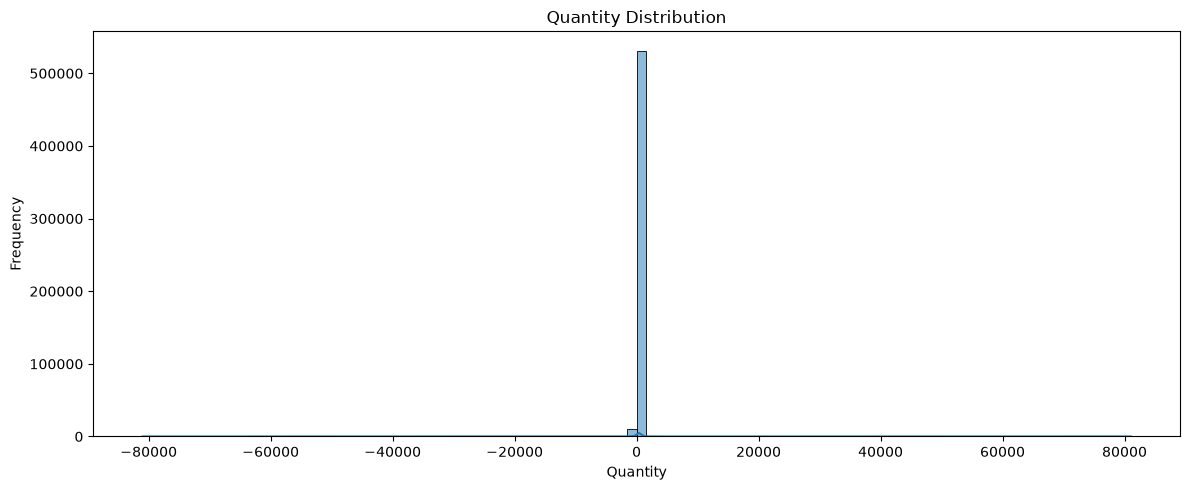

In [35]:
plt.figure(figsize=(12, 5))

sns.histplot(
    audit_df["Quantity"].dropna(),
    bins=100,
    kde=True
)

plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

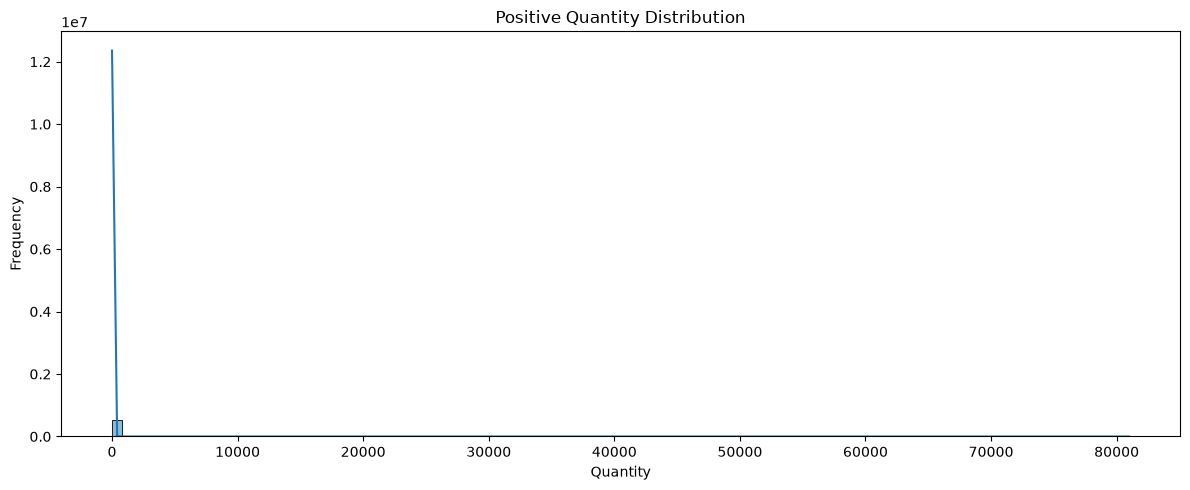

In [36]:
positive_quantity = audit_df.loc[
    audit_df["Quantity"] > 0,
    "Quantity"
]

plt.figure(figsize=(12, 5))

sns.histplot(
    positive_quantity,
    bins=100,
    kde=True
)

plt.title("Positive Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

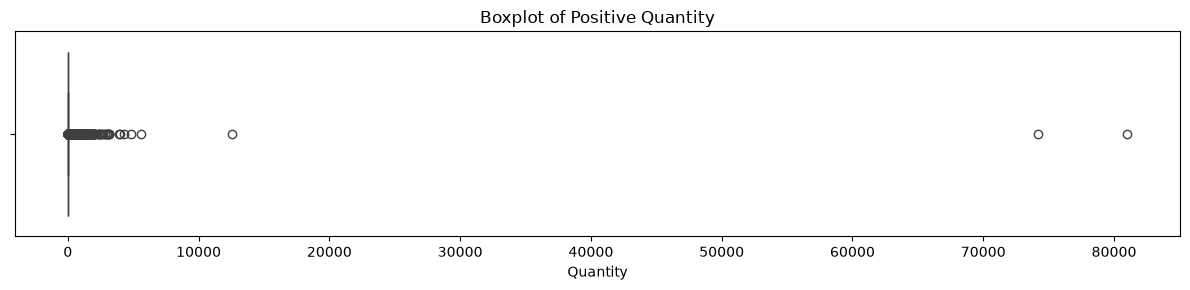

In [37]:
plt.figure(figsize=(12, 3))

sns.boxplot(x=positive_quantity)

plt.title("Boxplot of Positive Quantity")
plt.xlabel("Quantity")
plt.tight_layout()
plt.show()

### تفسیر توزیع Quantity

- توزیع کلی Quantity به‌تنهایی تصویر مناسبی از رفتار خرید نمی‌دهد؛ زیرا مقادیر منفی و مثبت بسیار بزرگ می‌توانند یکدیگر را در شاخص چولگی کل خنثی کنند.
- جفت‌های حدی حدود ‎+80,995 و ‎−80,995 باعث می‌شوند چولگی کل (حدود ‎−0.264) گمراه‌کننده باشد.
- در زیرمجموعه مقادیر مثبت، چولگی حدود 460 و کشیدگی حدود 119,769 است؛ بنابراین توزیع مثبت به‌شدت راست‌چوله و دارای دنباله سنگین است.
- مقادیر بزرگ مثبت لزوماً خطا نیستند و ممکن است خرید عمده باشند. مقادیر منفی نیز باید با شناسه فاکتور، مشتری، محصول و قیمت بررسی شوند.

**اثر بر اهداف:** Quantity خام برای فاصله‌سنجی خوشه‌بندی مناسب نیست و می‌تواند تحت تأثیر مقادیر حدی قرار گیرد.

**تصمیم برای Data Preparation:** خرید، لغو، مرجوعی و تعدیل موجودی تفکیک شوند؛ سپس در صورت نیاز تبدیل لگاریتمی یا روش مقاوم به داده پرت ارزیابی شود.

## محاسبه چولگی

In [38]:
quantity_skewness = audit_df["Quantity"].skew()

print("Quantity Skewness:", quantity_skewness)

Quantity Skewness: -0.26407630706692015


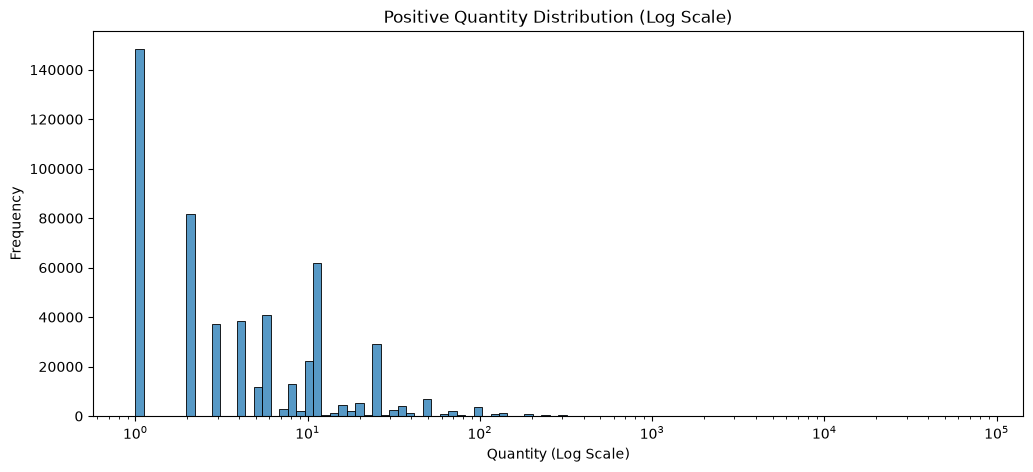

In [39]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=audit_df[audit_df["Quantity"] > 0],
    x="Quantity",
    bins=100,
    log_scale=(True, False)
)

plt.title("Positive Quantity Distribution (Log Scale)")
plt.xlabel("Quantity (Log Scale)")
plt.ylabel("Frequency")
plt.show()

### تحلیل توزیع و چولگی Quantity

چولگی کل Quantity حدود ‎−0.264 است؛ اما این عدد به‌تنهایی بیانگر شکل توزیع خرید نیست. مقادیر مثبت و منفی بسیار بزرگ (از جمله جفت‌های حدود ‎±80,995) می‌توانند اثر یکدیگر را در شاخص کل خنثی کنند.

در زیرمجموعه Quantity مثبت، چولگی حدود 460 و کشیدگی حدود 119,769 گزارش شده است. این اعداد نشان‌دهنده دنباله بسیار سنگین در سمت راست هستند. بنابراین باید توزیع مثبت و منفی جداگانه بررسی شود و نتیجه‌گیری درباره رفتار خرید صرفاً بر مبنای چولگی کل انجام نشود.

**تصمیم برای Data Preparation:** نوع تراکنش‌ها پیش از محاسبه ویژگی‌های مشتری تعیین شود؛ مقادیر مثبت بزرگ بدون بررسی حذف نشوند.

In [40]:
positive_quantity = audit_df.loc[
    audit_df["Quantity"] > 0,
    "Quantity"
]

positive_quantity_skewness = positive_quantity.skew()

print("Positive Quantity Skewness:", positive_quantity_skewness)

Positive Quantity Skewness: 460.13096736600386


#### بررسی شاخص اماری 

In [41]:
audit_df["Quantity"].describe()

count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

#### محاسبه چولگی و کشیدگی 

In [42]:
print("Skewness:", audit_df["Quantity"].skew())

print("Kurtosis:", audit_df["Quantity"].kurt())

Skewness: -0.26407630706692015
Kurtosis: 119769.16003068589


#### بررسی مقادیر صفر و منفی

In [43]:
quantity_status = pd.DataFrame({
    "Count": [
        (audit_df["Quantity"] < 0).sum(),
        (audit_df["Quantity"] == 0).sum(),
        (audit_df["Quantity"] > 0).sum()
    ]
}, index=[
    "Negative Quantity",
    "Zero Quantity",
    "Positive Quantity"
])

display(quantity_status)

,Count
Negative Quantity,10624
Zero Quantity,0
Positive Quantity,531285


#### شناسایی مقادیر بسیار بزرگ 

In [44]:
audit_df["Quantity"].sort_values(ascending=False).head(10)

540421    80995
61619     74215
502122    12540
74614      5568
421632     4800
206121     4300
220843     4000
97432      3906
270885     3186
160546     3114
Name: Quantity, dtype: int64

#### بررسی مقادیر منفی بزرگ

In [45]:
audit_df["Quantity"].sort_values().head(10)

540422   -80995
61624    -74215
225529    -9600
225530    -9600
4287      -9360
225528    -9058
115818    -5368
431381    -4830
341601    -3667
323458    -3167
Name: Quantity, dtype: int64

#### بررسی رکورد های دارای مقادیر بسیار بزرگ

In [46]:
audit_df.loc[
    audit_df["Quantity"].abs() >= 10000,
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID", "Country"]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,United Kingdom
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0,United Kingdom
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,13256.0,United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0,United Kingdom


#### رسم نمودار

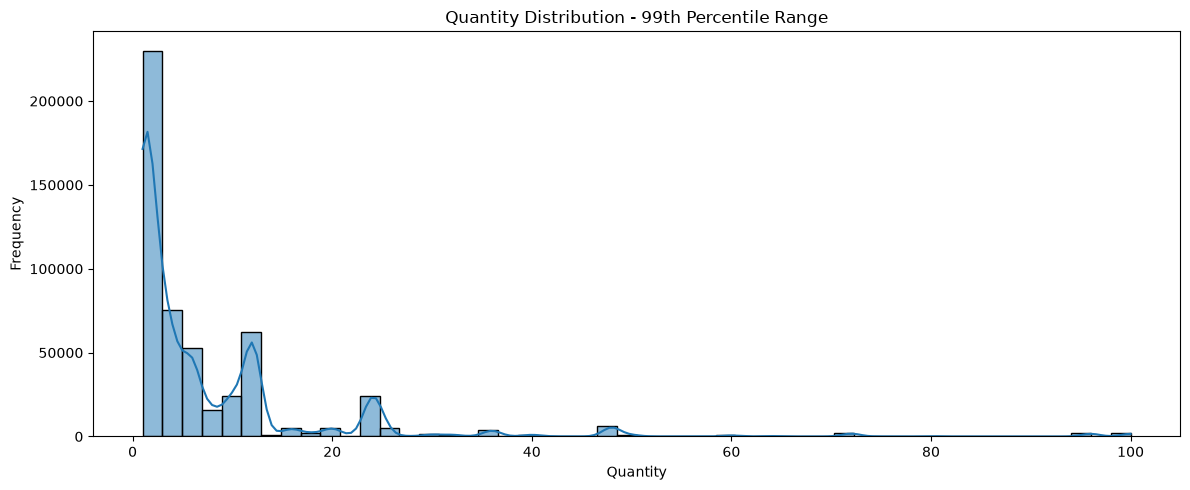

In [47]:
upper_limit = audit_df["Quantity"].quantile(0.99)

plt.figure(figsize=(12, 5))

sns.histplot(
    audit_df.loc[
        audit_df["Quantity"].between(0, upper_limit),
        "Quantity"
    ],
    bins=50,
    kde=True
)

plt.title("Quantity Distribution - 99th Percentile Range")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**بلند ترین ستونهای نمودار در مقادیر پایین قرار دارند بنابراین تعداد زیادی از تراکنش ها مربوط به خرید با تعداد کم کالا است**

**هدف از این بررسی ها این است که متوجه بشیم تعداد این کالا درست ثبت شده است یا دارای مقادیر پرت هست**

In [48]:
audit_df.loc[
    audit_df["Quantity"].abs() >= 10000,
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country",
        "IsCancellation"
    ]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country,IsCancellation
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,United Kingdom,False
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0,United Kingdom,True
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,13256.0,United Kingdom,False
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,United Kingdom,False
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0,United Kingdom,True


In [49]:
audit_df.loc[
    audit_df["Quantity"].abs() >= 10000,
    [
        "InvoiceNo",
        "InvoiceDate",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "IsCancellation"
    ]
].sort_values(by=["StockCode", "InvoiceDate"])

,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,CustomerID,IsCancellation
61619,541431,1/18/2011 10:01,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,False
61624,C541433,1/18/2011 10:17,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0,True
540421,581483,12/9/2011 9:15,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,False
540422,C581484,12/9/2011 9:27,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0,True
502122,578841,11/25/2011 15:57,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,13256.0,False


بررسی ردیف‌های Quantity منفی نشان می‌دهد که برخی موارد با خرید قبلی همان مشتری و محصول تطابق دارند؛ با این حال، تطابق مقدار و محصول باید در سطح مشتری، کد کالا و ترتیب زمانی انجام شود. تطابق ساده دو ردیف مشابه برای نتیجه‌گیری قطعی درباره مرجوعی کافی نیست. موارد فاقد CustomerID و دارای قیمت صفر باید جداگانه به‌عنوان تعدیل موجودی بررسی شوند.

#### بررسی شاخص اماری UnitPrice

In [50]:
audit_df["UnitPrice"].describe()

count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

**با توجه به مشاهده مقادیر میانگین و میانه مت.جه میشیم که این دو اختلاف زیادی دارند که نشان میدهد تعدادی کالا با قیمت بسیار بزرگ وجود دارد **

#### محاسبه چولگی و کشیدگی

In [51]:
print("Skewness:", audit_df["UnitPrice"].skew())

print("Kurtosis:", audit_df["UnitPrice"].kurt())

Skewness: 186.50697172054143
Kurtosis: 59005.71909694808


- طبق خروجی تصویر:
چولگی حدود ۱۸۶.۵ است.
کشیدگی حدود ۵۸۰۰۵ است.
این اعداد نشان می‌دهند:
- چولگی (Skewness):
چولگی بسیار مثبت است؛ یعنی توزیع قیمت‌ها به‌شدت به سمت راست کشیده شده و تعداد محدودی قیمت بسیار بزرگ در آن وجود دارد.
- کشیدگی (Kurtosis):
مقدار بسیار زیاد کشیدگی نشان‌دهنده دنباله‌های سنگین و وجود مقادیر بسیار دورافتاده نسبت به بخش عمده داده‌هاست.
- پس توزیع قیمت‌ها نرمال و متقارن نیست.

#### بررسی قیمت منفی و صفر 

In [52]:
price_status = pd.DataFrame({
    "Count": [
        (audit_df["UnitPrice"] < 0).sum(),
        (audit_df["UnitPrice"] == 0).sum(),
        (audit_df["UnitPrice"] > 0).sum()
    ]
}, index=[
    "Negative Price",
    "Zero Price",
    "Positive Price"
])

display(price_status)

,Count
Negative Price,2
Zero Price,2515
Positive Price,539392


**در اینجا مشاهده میشود که 2515 رکورد دارای مقادیر 0 هستند که باید مورد بررسی قرار بگیرد**

In [53]:
audit_df.loc[
    audit_df["UnitPrice"] <= 0,
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country",
        "IsCancellation"
    ]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country,IsCancellation
622,536414,22139,NaN,56,0.0,NaN,United Kingdom,False
1970,536545,21134,NaN,1,0.0,NaN,United Kingdom,False
1971,536546,22145,NaN,1,0.0,NaN,United Kingdom,False
1972,536547,37509,NaN,1,0.0,NaN,United Kingdom,False
1987,536549,85226A,NaN,1,0.0,NaN,United Kingdom,False
...,...,...,...,...,...,...,...,...
536981,581234,72817,NaN,27,0.0,NaN,United Kingdom,False
538504,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,0.0,NaN,United Kingdom,False
538505,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,0.0,NaN,United Kingdom,False
538554,581408,85175,NaN,20,0.0,NaN,United Kingdom,False


**در اینجا مقادیر صفر مشاهده میشود که دارای تعداد کالای مثبت است که این نتیجه غیر عادی است و اگر بخواهیم مبلغ خرید را حساب کنیم حاصل ضربش در صفر مساوی صفر میشود **

In [54]:
pd.crosstab(
    audit_df["IsCancellation"],
    audit_df["UnitPrice"] <= 0,
    margins=True
)

UnitPrice,False,True,All
IsCancellation,,,
False,530104,2517,532621
True,9288,0,9288
All,539392,2517,541909


جدول تقاطعی نشان می‌دهد ردیف‌های Quantity منفی یا UnitPrice صفر را نمی‌توان همگی به لغو سفارش نسبت داد. به‌ویژه، **1,336 ردیف Quantity منفی بدون C** دارای UnitPrice صفر و CustomerID گمشده‌اند و الگوی توضیحات آن‌ها با تعدیل موجودی سازگار است.

**تصمیم:** این گروه از مرجوعی مشتری تفکیک و از محاسبه فروش و سبد خرید محصولی کنار گذاشته شود. فاکتورهای C نیز در گروه لغو/برگشت باقی بمانند تا با خرید قبلی تطبیق داده شوند.

In [55]:
audit_df.loc[
    audit_df["UnitPrice"] < 0,
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country",
        "IsCancellation"
    ]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country,IsCancellation
299983,A563186,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom,False
299984,A563187,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom,False


#### بررسی اینکه چرا چولگی قیمت به شدن مثبت شده 

In [56]:
audit_df["UnitPrice"].sort_values(
    ascending=False
).head(10)

222681    38970.00
524602    17836.46
43702     16888.02
43703     16453.71
16356     13541.33
15016     13541.33
15017     13541.33
16232     13474.79
524601    11586.50
299982    11062.06
Name: UnitPrice, dtype: float64

- قیمت ها در مقایسع با میانه بسیار بزرگ هستند ولی هنوز نمیتوانیم بگوییم این قیمت ها اشتباه ثبت شده اند شاید مربوط به کالا های گران قیمت یا ثبت های خاص باشد

#### بررسی قیمت های بسیار پایین 

In [57]:
audit_df["UnitPrice"].sort_values().head(10)

299983   -11062.06
299984   -11062.06
204602        0.00
387137        0.00
387138        0.00
387139        0.00
423946        0.00
204603        0.00
204604        0.00
387140        0.00
Name: UnitPrice, dtype: float64

#### بررسی اینکه قیمت های بسیار بزرگ مربوط به چه کالاهایی هستند 

In [58]:
audit_df.loc[
    audit_df["UnitPrice"] >= 1000,
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country",
        "IsCancellation"
    ]
].sort_values(
    by="UnitPrice",
    ascending=False
).head(20)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country,IsCancellation
222681,C556445,M,Manual,-1,38970.00,15098.0,United Kingdom,True
524602,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,NaN,United Kingdom,True
43702,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,NaN,United Kingdom,True
43703,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,NaN,United Kingdom,True
16356,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,NaN,United Kingdom,True
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,NaN,United Kingdom,False
15016,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,NaN,United Kingdom,True
16232,C537644,AMAZONFEE,AMAZON FEE,-1,13474.79,NaN,United Kingdom,True
524601,C580604,AMAZONFEE,AMAZON FEE,-1,11586.50,NaN,United Kingdom,True
299982,A563185,B,Adjust bad debt,1,11062.06,NaN,United Kingdom,False


- در ابتا تصور میشد تمام قیمت های بالا برای محصولات گران قیمت یا سفارشا خاصی هستش که ثبت شده اند ولی در اینجا میفهمیم بخشی از انها مربوط به هزینه های

- 1. هزینه های Amazon
- 2. هزینه های ارسال 
- 3. ثبت های دستی 
- 4. تعدیلات حسابداری

- بنابراین نباید مقادیر بزرگ را به عنوان واقعی کالا در نظر بگیریم

### بررسی CustomerID

In [59]:
customer_id_summary = pd.DataFrame({
    "Value": [
        audit_df["CustomerID"].dtype,
        len(audit_df),
        audit_df["CustomerID"].isna().sum(),
        audit_df["CustomerID"].notna().sum(),
        audit_df["CustomerID"].nunique()
    ]
}, index=[
    "Data Type",
    "Total Records",
    "Missing CustomerID",
    "Available CustomerID",
    "Unique Customers"
])

display(customer_id_summary)

,Value
Data Type,float64
Total Records,541909
Missing CustomerID,135080
Available CustomerID,406829
Unique Customers,4372


#### بررسی توزیع تعداد رکورد های مشتریان

In [60]:
customer_record_counts = (
    audit_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .size()
    .sort_values(ascending=False)
)

display(customer_record_counts.describe())

count    4372.000000
mean       93.053294
std       232.471608
min         1.000000
25%        17.000000
50%        42.000000
75%       102.000000
max      7983.000000
dtype: float64

#### بررسی تعداد فاکتور هر مشتری

In [61]:
customer_invoice_counts = (
    audit_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

display(customer_invoice_counts.head(10))

CustomerID
14911.0    248
12748.0    224
17841.0    169
14606.0    128
15311.0    118
13089.0    118
12971.0     89
14527.0     86
13408.0     81
14646.0     77
Name: InvoiceNo, dtype: int64

**در اینجا متوجه میشویم هر مشتری در این دیتاست در مجکوع چند بار خرید داشته است**

In [62]:
display(customer_invoice_counts.describe())

count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64

**در اینجا ما رفتار خرید مشتریان را تحلیل میکنیم**

- در شمارشی که قبلا انجام دادیم ممکن است فاکتور های لغو شده هم محاسبه شده باشند برای تحلیل رفتار خرید مشتریان بهتر است تعداد فاکتور های خرید معتبر را جداگانه محاسبه کنیم

In [63]:
# تعریف اکتشافی ردیف محصولی؛ اقلام خدماتی/هزینه‌ای و کدهای غیرمحصولی حذف نمی‌شوند،
# بلکه فقط از مجموعه خرید محصولی برای ویژگی‌های مشتری کنار گذاشته می‌شوند.
NON_PRODUCT_CODES = {
    "POST", "DOT", "M", "D", "BANK CHARGES", "AMAZONFEE", "CRUK"
}

stockcode_text = audit_df["StockCode"].astype("string").str.strip().str.upper()
description_text = audit_df["Description"].astype("string").str.strip().str.lower()

is_non_product = (
    stockcode_text.isin(NON_PRODUCT_CODES)
    | stockcode_text.str.startswith("GIFT_", na=False)
    | description_text.str.contains(
        r"amazon fee|postage|bank charge|manual|adjust bad debt",
        na=False,
        regex=True
    )
)

audit_df["IsNonProduct"] = is_non_product
audit_df["IsCancellation"] = (
    audit_df["InvoiceNo"].astype("string").str.strip().str.upper().str.startswith("C", na=False)
)

valid_customer_transactions = audit_df[
    (~audit_df["IsCancellation"])
    & (~audit_df["IsNonProduct"])
    & (audit_df["Quantity"] > 0)
    & (audit_df["UnitPrice"] > 0)
    & (audit_df["CustomerID"].notna())
    & (audit_df["InvoiceDate"].notna())
].copy()

valid_customer_transactions["TotalPrice"] = (
    valid_customer_transactions["Quantity"] * valid_customer_transactions["UnitPrice"]
)

customer_invoice_counts = (
    valid_customer_transactions.groupby("CustomerID")["InvoiceNo"].nunique()
)
display(customer_invoice_counts.describe())
print("Valid customer count:", customer_invoice_counts.index.nunique())

count    4334.000000
mean        4.246654
std         7.642535
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       206.000000
Name: InvoiceNo, dtype: float64

Valid customer count: 4334


#### بررسی توزیع تعداد فاکتورهای مشتریان

پس از حذف فاکتورهای لغوشده، ردیف‌های دارای تعداد و قیمت غیرمثبت و رکوردهای فاقد شناسه مشتری، تعداد فاکتورهای یکتای هر مشتری محاسبه شد.

نتایج نشان داد:

- تعداد مشتریان دارای خرید معتبر برابر با ۴۳۳۸ نفر است.
- میانگین تعداد فاکتور هر مشتری ۴.۲۷ است.
- میانه تعداد فاکتورها برابر با ۲ است.
- ۷۵ درصد مشتریان حداکثر ۵ فاکتور ثبت کرده‌اند.
- بیشترین تعداد فاکتور متعلق به یک مشتری برابر با ۲۰۹ است.

- . نتیجه‌گیری:

توزیع تعداد فاکتورهای مشتریان نامتوازن است و احتمال وجود چولگی به راست در آن مشاهده می‌شود. بیشتر مشتریان تعداد فاکتورهای کمی دارند، درحالی‌که تعداد محدودی از مشتریان دفعات خرید بسیار بیشتری ثبت کرده‌اند.

این تفاوت در رفتار خرید، ضرورت بررسی و بخش‌بندی مشتریان را در مراحل بعدی پروژه نشان می‌دهد.

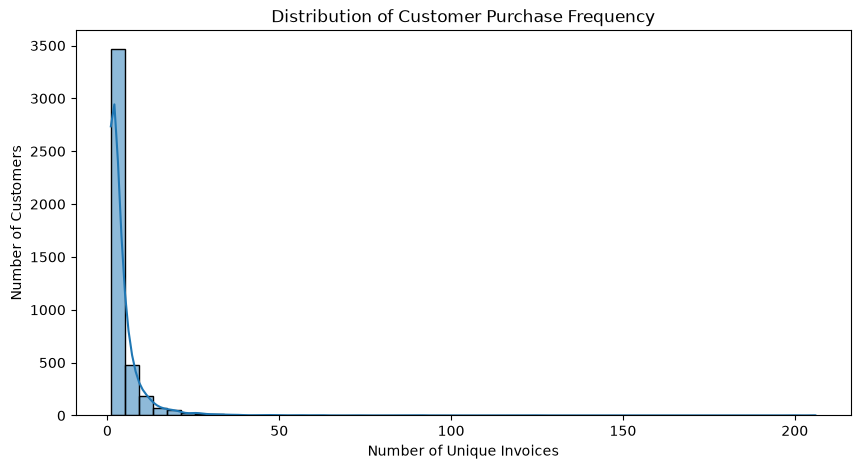

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    customer_invoice_counts,
    bins=50,
    kde=True
)

plt.title("Distribution of Customer Purchase Frequency")
plt.xlabel("Number of Unique Invoices")
plt.ylabel("Number of Customers")

plt.show()

#### تحلیل توزیع Frequency مشتریان

تعداد مشتریان دارای حداکثر دو فاکتور خرید معتبر برابر با **۲٬۳۲۸ نفر** از مجموع **۴٬۳۳۸ مشتری** است. از این تعداد، **۱٬۴۹۳ مشتری دقیقاً یک فاکتور** معتبر دارند.

این اعداد با عبارت «۳٬۵۰۰ مشتری فقط یک یا دو بار خرید کرده‌اند» سازگار نیستند. توزیع Frequency نامتوازن است و وجود مشتریان کم‌تکرار و پرتکرار را نشان می‌دهد.

**اثر بر اهداف:** Frequency یکی از ویژگی‌های مهم پروفایل مشتری و بخش‌بندی است؛ اما تعداد فاکتور باید فقط از خریدهای معتبر محاسبه شود.

**تصمیم برای Data Preparation:** فاکتورهای لغوشده و ردیف‌های غیرخرید از محاسبه Frequency کنار گذاشته شوند. در این مرحله هیچ استراتژی جذب یا وفادارسازی پیشنهاد نمی‌شود.

### بررسی مبلغ خرید مشتریان 

- تااینجا فهمیدیم هر مشتری چند فاکتور خرید معتبر داشته . حالا باید بفهمیم هر مشتری در مجموع چه مقدار خرید کرده است

##### محاسبه مبلغ خرید هر ردیف

In [65]:
valid_customer_transactions["TotalPrice"] = (
    valid_customer_transactions["Quantity"] *
    valid_customer_transactions["UnitPrice"]
)

In [66]:
display(
    valid_customer_transactions[
        ["Quantity", "UnitPrice", "TotalPrice"]
    ].head(10)
)

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
5,2,7.65,15.30
6,6,4.25,25.50
7,6,1.85,11.10
8,6,1.85,11.10
9,32,1.69,54.08


In [67]:
customer_monetary = (
    valid_customer_transactions
    .groupby("CustomerID")["TotalPrice"]
    .sum()
)

display(customer_monetary.describe())

count      4334.000000
mean       2023.016302
std        8924.198162
min           3.750000
25%         305.867500
50%         668.125000
75%        1631.622500
max      279138.020000
Name: TotalPrice, dtype: float64

#### توزیع Monetary با رسم نمودار 

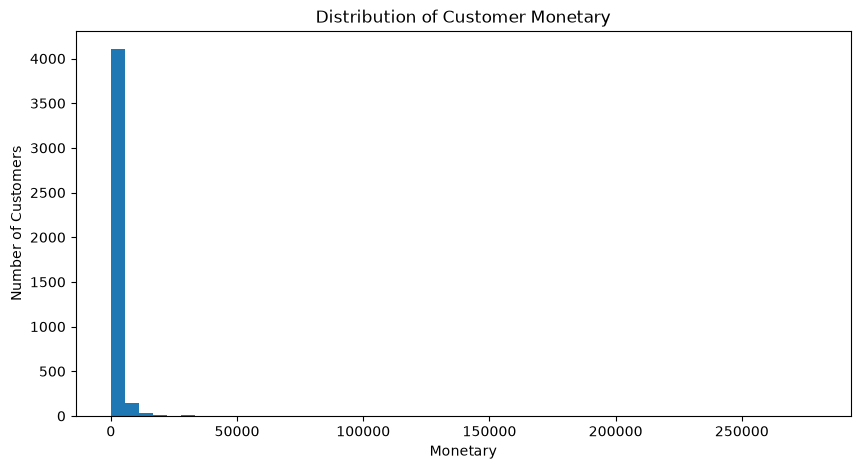

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(customer_monetary, bins=50)

plt.title("Distribution of Customer Monetary")
plt.xlabel("Monetary")
plt.ylabel("Number of Customers")

plt.show()

#### تحلیل توزیع Monetary مشتریان

توزیع Monetary راست‌چوله است؛ اما ادعای وابستگی درآمد به تعداد کمی مشتری باید با سهم تجمعی مشتریان پشتیبانی شود. محاسبه روی خریدهای معتبر نشان می‌دهد:

- ۱۰٪ بالایی مشتریان حدود **۶۱٪** از ارزش خرید معتبر را تشکیل می‌دهند.
- ۱٪ بالایی مشتریان حدود **۳۲٪** از ارزش خرید معتبر را تشکیل می‌دهند.

بنابراین تمرکز ارزش خرید در بخش کوچکی از مشتریان قابل مشاهده است؛ با این حال Monetary در این مرحله شاخص ارزش خرید ثبت‌شده است و معادل سود خالص یا Customer Lifetime Value نیست.

**اثر بر اهداف:** این تمرکز، ضرورت بررسی مقیاس‌بندی و تبدیل ویژگی‌های اقتصادی در خوشه‌بندی و تعریف شفاف Customer Value Score را نشان می‌دهد.

**تصمیم برای Data Preparation:** Monetary فقط از خریدهای محصولی معتبر محاسبه شود و اقلام غیرمحصولی، لغوها و تعدیلات از آن جدا شوند.

### رسم نمودار لگاریتمی 

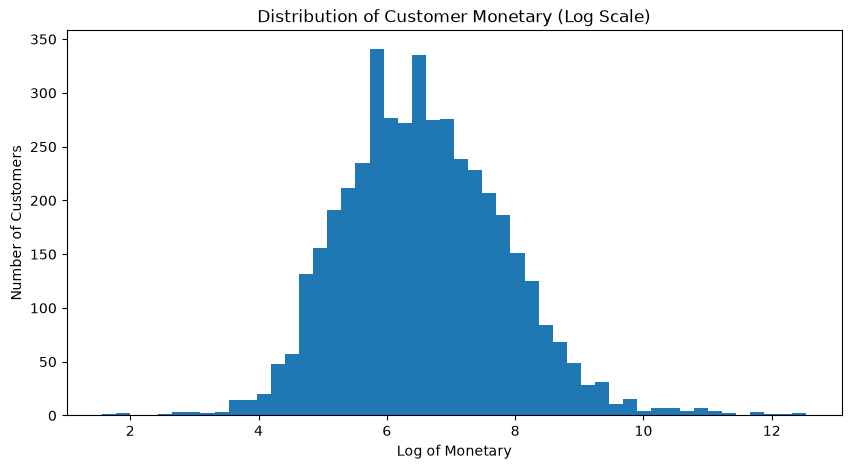

In [69]:
import numpy as np

plt.figure(figsize=(10, 5))

plt.hist(np.log1p(customer_monetary), bins=50) 

plt.title("Distribution of Customer Monetary (Log Scale)")
plt.xlabel("Log of Monetary")
plt.ylabel("Number of Customers")
plt.show()

**ایتفاده از نمودار لگاریتمی برای درک بهتر از مبالغ خرید مشتری**

- باعث :
- کاهش اثر مقادیر بزرگ روی شکل نمودار 
- قابل مشاهده تر شدن توزیع مشتریان با مبالغ خرید 

#### Frequency(تعذاذ فاکتور های هر مشتری)

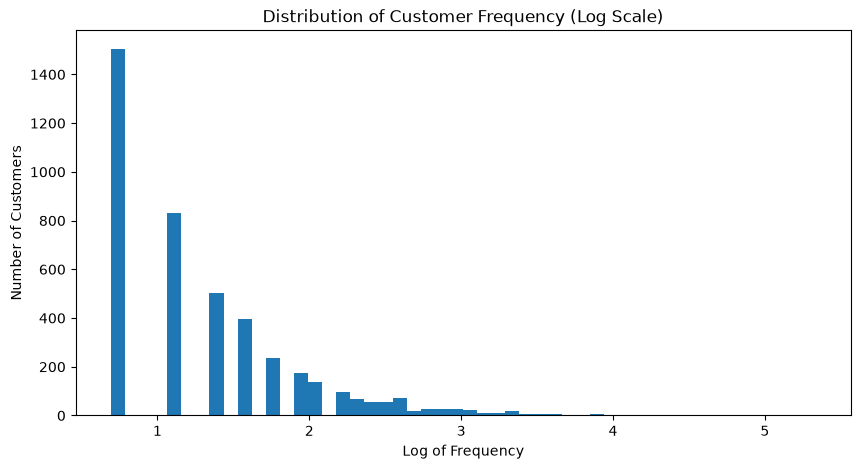

In [70]:
plt.figure(figsize=(10, 5))

plt.hist(np.log1p(customer_invoice_counts), bins=50)

plt.title("Distribution of Customer Frequency (Log Scale)")
plt.xlabel("Log of Frequency")
plt.ylabel("Number of Customers")

plt.show()

- تحلیل نمودار :

- این نمودار شمای بهتری را نشان میدهد 

- این نمودار غالب بودن مشتریانی را نشان میدهد که تنها یک بار خرید کرده اند 

- با حرکت به سمت راست ارتفاع ستون ستون کمتر شده و نشاندهنده مشتریانی است که خرید بیشتری دارند 

#### Quantity(تعداد کالا)

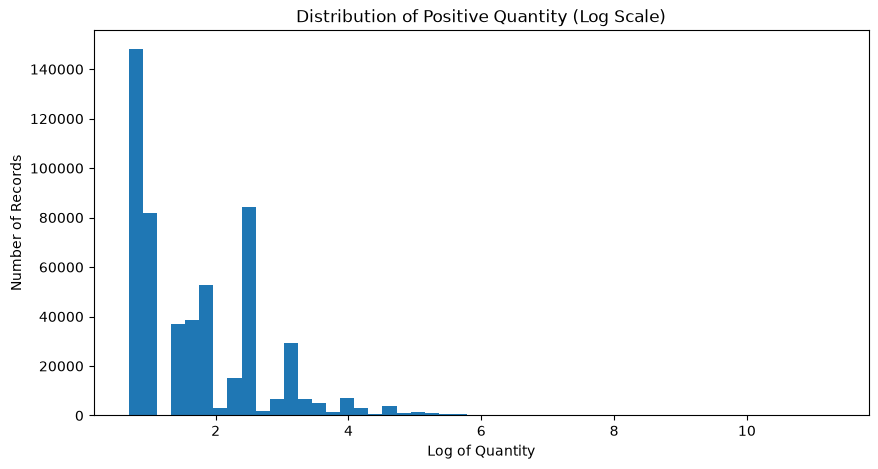

In [71]:
positive_quantity = audit_df.loc[
    audit_df["Quantity"] > 0,
    "Quantity"
]

plt.figure(figsize=(10, 5))

plt.hist(np.log1p(positive_quantity), bins=50)

plt.title("Distribution of Positive Quantity (Log Scale)")
plt.xlabel("Log of Quantity")
plt.ylabel("Number of Records")

plt.show()

- تحلیل نمودار :

- با توجه به این که تعداد کالا در دیتاست ما دارای مقادیر منفی است برای رسم این نمودار مقادیر منفی را لحاظ نمیکنیم 

- نکته متفاوتی که در این نمودار وجود دارد وجود چند قله است که موضوع طبیعی در این سناریو است چرا که بخشی از مشتریان این فروشگاه انلاین عمده فروشان هستند 

- تبدیل لگاریتمی باعث شده که بتوانیم هر دو گروه مشتریان خرد و مشتریان عمده را در یک نمودار ببینیم 

### بررسی اکتشافی Recency

Recency فاصله آخرین **خرید معتبر** مشتری تا یک تاریخ مرجع را نشان می‌دهد. در این مرحله فقط یک محاسبه اکتشافی برای شناخت رفتار داده انجام می‌شود؛ نسخه نهایی RFM، تعریف دقیق خرید معتبر و تاریخ‌های مرجع متعدد در Data Preparation و Feature Engineering ساخته خواهند شد.

در این بررسی، فاکتورهای لغوشده، ردیف‌های غیرمحصولی، ردیف‌های با Quantity یا UnitPrice غیرمثبت و رکوردهای فاقد CustomerID نباید به‌عنوان خرید معتبر در نظر گرفته شوند. بنابراین آخرین ردیف خام مشتری مبنای Recency نیست.

##### بررسی تاریخ های داده ها 

In [72]:
print("Earliest Date:", audit_df["InvoiceDate"].min())
print("Latest Date:", audit_df["InvoiceDate"].max())
print("Total Unique Timestamps:", audit_df["InvoiceDate"].nunique())
print("Invalid / unparsed dates:", audit_df["InvoiceDate"].isna().sum())

Earliest Date: 1/10/2011 10:04
Latest Date: 9/9/2011 9:52
Total Unique Timestamps: 23260
Invalid / unparsed dates: 0


### انتخاب تاریخ مرجع

**ابتدا تبدیل TnvoiceDate از str به datetime**

In [73]:
# اطمینان از تبدیل InvoiceDate به datetime
audit_df["InvoiceDate"] = pd.to_datetime(
    audit_df["InvoiceDate"],
    errors="coerce"
)

# بررسی نوع داده پس از تبدیل
print("InvoiceDate dtype:", audit_df["InvoiceDate"].dtype)

# بررسی تعداد تاریخ‌های نامعتبر
invalid_dates = audit_df["InvoiceDate"].isna().sum()
print("Invalid InvoiceDate values:", invalid_dates)

InvoiceDate dtype: datetime64[us]
Invalid InvoiceDate values: 0


In [74]:
print(audit_df["InvoiceDate"].dtype)

datetime64[us]


##### بررسی کمترین و بیشترین تاریخ 

In [75]:
print("Earliest Date:", audit_df["InvoiceDate"].min())
print("Latest Date:", audit_df["InvoiceDate"].max())

Earliest Date: 2010-12-01 08:26:00
Latest Date: 2011-12-09 12:50:00


In [76]:
monthly_transactions = (
    audit_df
    .set_index("InvoiceDate")
    .resample("ME")
    .size()
)

display(monthly_transactions)

InvoiceDate
2010-12-31    42481
2011-01-31    35147
2011-02-28    27707
2011-03-31    36748
2011-04-30    29916
2011-05-31    37030
2011-06-30    36874
2011-07-31    39518
2011-08-31    35284
2011-09-30    50226
2011-10-31    60742
2011-11-30    84711
2011-12-31    25525
Freq: ME, dtype: int64

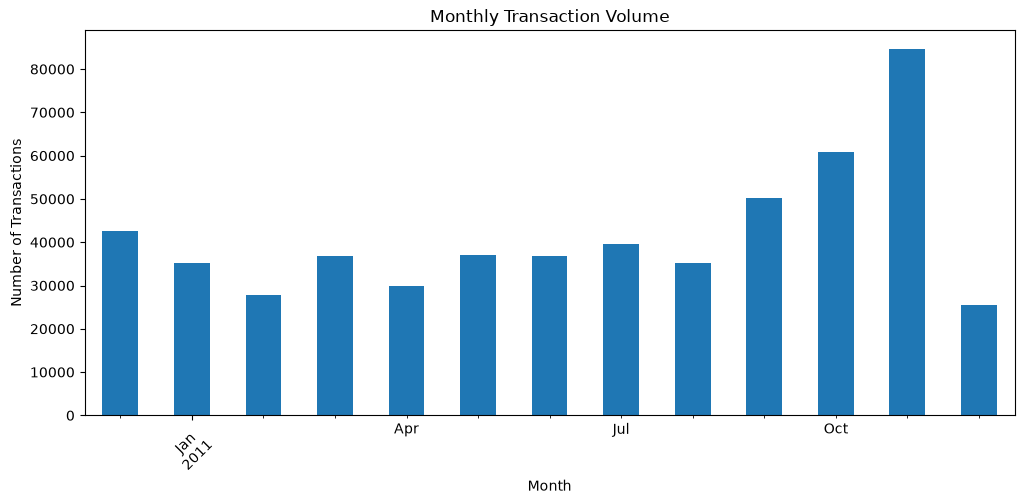

In [77]:
monthly_transactions.plot(
    kind="bar",
    figsize=(12, 5),
    title="Monthly Transaction Volume"
)

plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.show()

- تحلیل نمودار 

- برای درک بهتری از رفتار خرید فصلی مشتریان و الگوی زمانی فروش و حجم تراکنش های ماهانه این نمودار رسم شده است . همان طور که در نمودار قابل مشاهده است حجم تراکنش ها در نیمه اول سال روندی نسبتا ثابت دارد اما از ماه سپتامبر شاهد روند چشمگیری هستیم که در ماه نوامبر به اوج خود میرسد 

- این پدیده نشان دهنده یک الگوی فصلی قوی است که میتواند ناشی از کمپین های فروش پاییزه و اماده سازی برای کریسمس باشد 

- همچنین میتوان افت شدید تراکنش هارا به دلیل ناقص بودن داده ها یا اتمام خرید های هدیه در ماه قبل دانست 

#### محاسبه تعداد مشتریان یکتا هر ماه 

In [78]:
# تبدیل InvoiceDate به datetime در دیتافریم مورد استفاده
valid_customer_transactions["InvoiceDate"] = pd.to_datetime(
    valid_customer_transactions["InvoiceDate"],
    errors="coerce"
)

# حذف ردیف‌هایی که تاریخ معتبر ندارند
valid_customer_transactions = valid_customer_transactions.dropna(
    subset=["InvoiceDate"]
)

# محاسبه تعداد مشتریان فعال در هر ماه
monthly_customers = (
    valid_customer_transactions
    .assign(
        Month=valid_customer_transactions["InvoiceDate"].dt.to_period("M")
    )
    .groupby("Month")["CustomerID"]
    .nunique()
)

display(monthly_customers.to_frame("Valid Active Customers"))

,Valid Active Customers
Month,
2010-12,884
2011-01,739
2011-02,757
2011-03,973
2011-04,853
2011-05,1054
2011-06,990
2011-07,946
2011-08,933


- تعداد مشتریان فعال ماهانه بر اساس فاکتورهای خرید معتبر و محصولی محاسبه شده است.
- دسامبر ۲۰۱۱ فقط تا روز ۹ دسامبر در دیتاست پوشش دارد؛ بنابراین مقایسه آن با ماه‌های کامل قابل اتکا نیست و افت آن باید با احتیاط تفسیر شود.
- این تحلیل صرفاً الگوی فعالیت تاریخی را توصیف می‌کند و برچسب ریزش یا پیش‌بینی آینده تولید نمی‌کند.

### بررسی روند درامد ماهانه

In [79]:
monthly_revenue = (
    audit_df
    .assign(
        TotalPrice=audit_df["Quantity"] * audit_df["UnitPrice"]
    )
    .set_index("InvoiceDate")
    .resample("ME")["TotalPrice"]
    .sum()
)

display(monthly_revenue)

InvoiceDate
2010-12-31     748957.020
2011-01-31     560000.260
2011-02-28     498062.650
2011-03-31     683267.080
2011-04-30     493207.121
2011-05-31     723333.510
2011-06-30     691123.120
2011-07-31     681300.111
2011-08-31     682680.510
2011-09-30    1019687.622
2011-10-31    1070704.670
2011-11-30    1461756.250
2011-12-31     433668.010
Freq: ME, Name: TotalPrice, dtype: float64

- بررسی تغییرات ارزش تراکنش‌ها در طول زمان

- به‌منظور شناخت روند تغییرات ارزش اقتصادی تراکنش‌ها، مجموع حاصل‌ضرب تعداد کالا در قیمت واحد برای هر ماه محاسبه شد. نتایج نشان داد که بیشترین مجموع ارزش تراکنش‌ها مربوط به نوامبر ۲۰۱۱ با مقدار 1,461,756.25 و کمترین مقدار مربوط به دسامبر ۲۰۱۱ با مقدار 433,668.01 بوده است.

- همچنین از سپتامبر تا نوامبر افزایش قابل‌توجهی در ارزش تراکنش‌ها مشاهده شد. با توجه به اینکه در این مرحله داده‌ها هنوز از نظر لغو سفارش‌ها و سایر رکوردهای غیرعادی پاک‌سازی نشده‌اند، مقادیر محاسبه‌شده به‌عنوان ارزش خام تراکنش‌ها در نظر گرفته می‌شوند.

#### محاسبه Recency مشتریان 

In [80]:
# Recency اکتشافی بر مبنای آخرین خرید معتبر و فقط برای شناخت توزیع
reference_date_exploratory = audit_df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_last_valid_purchase = (
    valid_customer_transactions
    .groupby("CustomerID")["InvoiceDate"]
    .max()
)
customer_recency = (reference_date_exploratory - customer_last_valid_purchase).dt.days

display(customer_recency.describe())
print("Customers with at least one valid purchase:", customer_recency.index.nunique())
print("Reference date (exploratory only):", reference_date_exploratory)

count    4334.000000
mean       92.703046
std       100.177047
min         1.000000
25%        18.000000
50%        51.000000
75%       143.000000
max       374.000000
Name: InvoiceDate, dtype: float64

Customers with at least one valid purchase: 4334
Reference date (exploratory only): 2011-12-10 12:50:00


- Recency در این مرحله بر اساس آخرین خرید معتبر هر مشتری محاسبه شده است؛ بنابراین با محاسبه مبتنی بر آخرین ردیف خام تفاوت دارد.
- مقدار کمتر Recency نشان‌دهنده خرید معتبر جدیدتر و مقدار بیشتر نشان‌دهنده فاصله طولانی‌تر از آخرین خرید معتبر است.
- این تاریخ مرجع واحد صرفاً برای تحلیل اکتشافی است و نباید به‌عنوان تاریخ مرجع نهایی مدل یا ارزیابی زمانی استفاده شود.
- تاریخ‌های مرجع متعدد و جلوگیری از نشت اطلاعات در Data Preparation و Feature Engineering طراحی خواهند شد.

#### رسم نمودار 

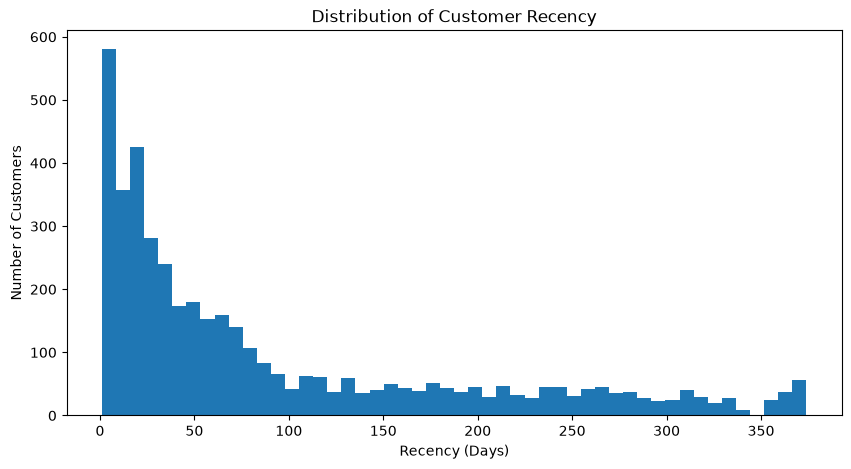

In [81]:
plt.figure(figsize=(10, 5))

plt.hist(customer_recency, bins=50)

plt.title("Distribution of Customer Recency")
plt.xlabel("Recency (Days)")
plt.ylabel("Number of Customers")

plt.show()

- توزیع Recency اکتشافی، فاصله زمانی مشتریان از آخرین خرید معتبر را نشان می‌دهد.
- دنباله بلند در سمت مقادیر بالاتر به معنای وجود مشتریانی است که مدت بیشتری از خرید معتبرشان گذشته است؛ این مشاهده به‌تنهایی پیش‌بینی ریزش محسوب نمی‌شود.
- به دلیل استفاده از یک تاریخ مرجع واحد، این خروجی صرفاً برای شناخت اولیه توزیع است.

#### بررسی کشور ها 

In [82]:
country_transactions = (
    audit_df["Country"]
    .value_counts()
)

display(country_transactions.head(15))

Country
United Kingdom     495478
Germany              9495
France               8557
EIRE                 8196
Spain                2533
Netherlands          2371
Belgium              2069
Switzerland          2002
Portugal             1519
Australia            1259
Norway               1086
Italy                 803
Channel Islands       758
Finland               695
Cyprus                622
Name: count, dtype: int64

- بررسی توریع تراکنش ها براساس کشور 

- همانطور که از خروجی کد مشخص است بیشترین رکورد های ثبت شده مربوط به بریتانیا است 

- پس از ان کشور های فرانسه و المان و EIRE قرار دارند 

#### بررسی محصولات پرفروش

In [83]:
top_products = (
    audit_df
    .groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

display(top_products.head(15))

StockCode
22197     56450
84077     53847
85099B    47363
85123A    38830
84879     36221
21212     36039
23084     30646
22492     26437
22616     26315
21977     24753
22178     23854
17003     23053
15036     22552
21915     22066
22386     21009
Name: Quantity, dtype: int64

- بررسی قطعه کد بالا 

- محصول 22197 بیشترین تعداد فروش ثبت شده را دارد 

- محصولات 84077 و 85099B در رتبه های بعدی قرار دارند 

- اختلاف محصولات ابتدای لیست با انتهای لیست بسیار قابل توجه است 

- به دلیل اینکه هنوز سفارشهای لغو شده و رکورد های غیرعادی جدا نشده اند این اعداد را نمیتوان فروش واقعی در نظر گرفت 

#### بررسی نام محصولات 

In [84]:
product_descriptions = (
    audit_df[
        ["StockCode", "Description"]
    ]
    .drop_duplicates()
)

display(
    product_descriptions[
        product_descriptions["StockCode"].isin(
            top_products.head(15).index
        )
    ].sort_values("StockCode")
)

,StockCode,Description
4402,15036,ASSORTED COLOURS SILK FAN
277041,15036,NaN
1849,17003,BROCADE RING PURSE
96,21212,PACK OF 72 RETROSPOT CAKE CASES
439,21915,RED HARMONICA IN BOX
478681,21915,John Lewis
98,21977,PACK OF 60 PINK PAISLEY CAKE CASES
449,22178,VICTORIAN GLASS HANGING T-LIGHT
223184,22197,POPCORN HOLDER
221,22197,SMALL POPCORN HOLDER


In [85]:
product_description_counts = (
    audit_df[
        audit_df["StockCode"].isin(top_products.head(15).index)
    ]
    .groupby(["StockCode", "Description"], dropna=False)
    .size()
    .sort_values(ascending=False)
)

display(product_description_counts)

StockCode  Description                        
85123A     WHITE HANGING HEART T-LIGHT HOLDER     2302
85099B     JUMBO BAG RED RETROSPOT                2159
84879      ASSORTED COLOUR BIRD ORNAMENT          1501
21212      PACK OF 72 RETROSPOT CAKE CASES        1385
22386      JUMBO BAG PINK POLKADOT                1251
22178      VICTORIAN GLASS HANGING T-LIGHT        1072
23084      RABBIT NIGHT LIGHT                     1051
21977      PACK OF 60 PINK PAISLEY CAKE CASES      896
22197      POPCORN HOLDER                          865
21915      RED  HARMONICA IN BOX                   676
22197      SMALL POPCORN HOLDER                    611
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS       542
22616      PACK OF 12 LONDON TISSUES               531
15036      ASSORTED COLOURS SILK FAN               523
22492      MINI PAINT SET VINTAGE                  390
17003      BROCADE RING PURSE                      245
23084      NaN                                      10
85123A     CREAM H

#### بررسی یکنواختی توضیحات محصولات

به‌منظور بررسی کیفیت اطلاعات محصولات، ارتباط میان شناسه محصول (StockCode) و توضیحات آن (Description) بررسی شد. نتایج نشان داد که برخی شناسه‌های محصول دارای چندین توضیح متفاوت هستند. همچنین تعدادی از توضیحات شامل عباراتی غیرمرتبط با نام محصول، مانند Amazon، damaged و temp adjustment بوده و برخی رکوردها نیز فاقد توضیحات محصول هستند.

این موارد نشان‌دهنده وجود ناهماهنگی در اطلاعات توصیفی محصولات است و لازم است در مرحله آماده‌سازی داده‌ها، پیش از استفاده از اطلاعات محصول در تحلیل‌های بعدی، مورد بررسی قرار گیرند.

#### بررسی ساختار فاکتورها

In [86]:
invoice_sizes = (
    audit_df
    .groupby("InvoiceNo")
    .size()
)

display(invoice_sizes.describe())

count    25900.000000
mean        20.923127
std         43.031334
min          1.000000
25%          2.000000
50%         10.000000
75%         23.000000
max       1114.000000
dtype: float64

#### محاسبه چولگی

In [87]:
print(
    "Invoice Size Skewness:",
    invoice_sizes.skew()
)

Invoice Size Skewness: 7.93856650759989


- بررسی چولگی تعداد ردیف‌های فاکتورها

مقدار چولگی توزیع تعداد ردیف‌های فاکتورها برابر با 7.94 محاسبه شد که نشان‌دهنده چولگی مثبت و شدید است. این نتیجه بیانگر آن است که بیشتر فاکتورها دارای تعداد ردیف‌های نسبتاً کمی هستند، درحالی‌که تعداد محدودی فاکتور با تعداد ردیف‌های بسیار زیاد وجود دارند. بنابراین، توزیع اندازه فاکتورها متقارن نیست و دارای دنباله‌ای بلند در سمت راست است.

##### رسم نمودار

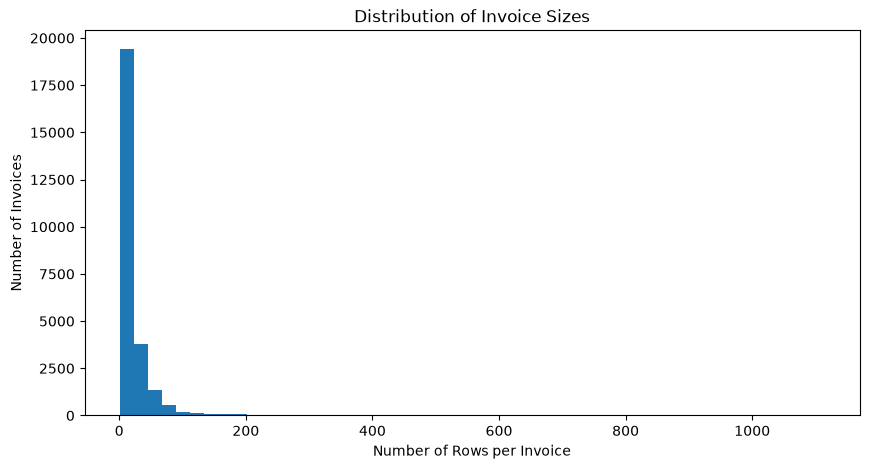

In [88]:
plt.figure(figsize=(10, 5))

plt.hist(invoice_sizes, bins=50)

plt.title("Distribution of Invoice Sizes")
plt.xlabel("Number of Rows per Invoice")
plt.ylabel("Number of Invoices")

plt.show()

- در فاکتورهای معتبر، میانه تعداد محصولات متمایز برابر با **۱۵ محصول** است.
- فقط **۸٫۲٪** فاکتورهای معتبر تک‌محصولی هستند.
- برداشت قبلی مبنی بر اینکه اغلب فاکتورها یک یا دو محصول دارند، تحت تأثیر فاکتورهای لغوشده و نامعتبر بوده است.

**اثر بر اهداف:** تنوع اقلام در فاکتورهای معتبر برای Association Rule Mining امیدوارکننده است و تشکیل سبد خرید معنا‌دار را ممکن می‌کند.

**تصمیم برای Data Preparation:** تحلیل اندازه سبد و ARM باید فقط بر فاکتورهای خرید معتبر و کدهای محصول واقعی انجام شود. این جدول ویژگی‌های سطح فاکتور است، نه سطح مشتری.

#### بررسی تعداد کالاهای خریداری شده هر فاکتور 

In [89]:
invoice_quantity = (
    audit_df
    .groupby("InvoiceNo")["Quantity"]
    .sum()
)

display(invoice_quantity.describe())

count    25900.000000
mean       199.862934
std       1108.563551
min     -80995.000000
25%          6.000000
50%        100.000000
75%        240.000000
max      80995.000000
Name: Quantity, dtype: float64

- همانطور که از نتیجه کد مشخص است میانگین با میانه اختلاف زیادی دارد

- مقادیر منفی و مثبت بسیار بزرگی داریم 

#### رسم نمودار 

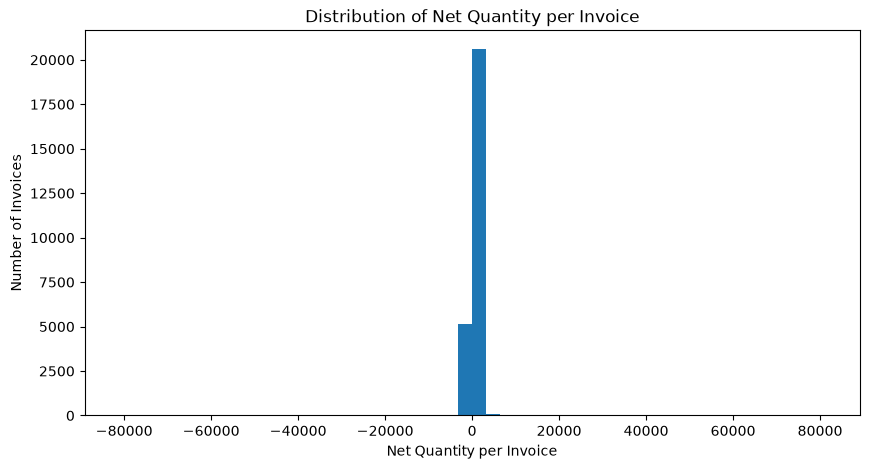

In [90]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(invoice_quantity, bins=50)

plt.title("Distribution of Net Quantity per Invoice")
plt.xlabel("Net Quantity per Invoice")
plt.ylabel("Number of Invoices")

plt.show()

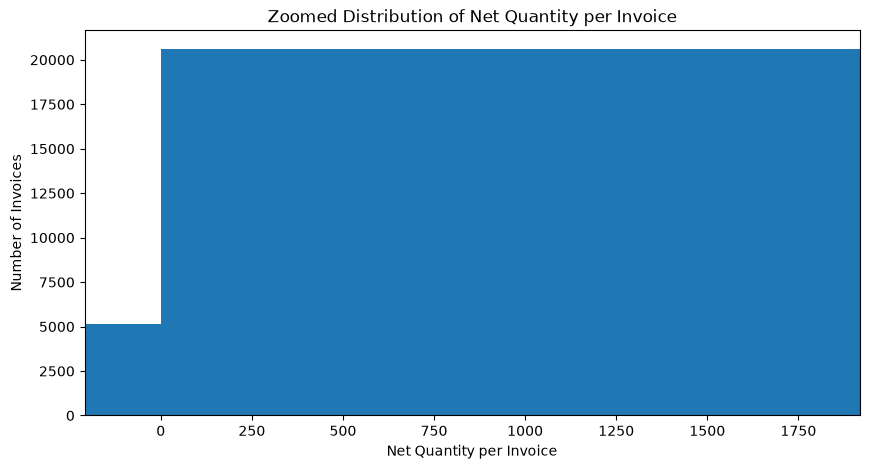

In [91]:
lower_limit = invoice_quantity.quantile(0.01)
upper_limit = invoice_quantity.quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(invoice_quantity, bins=50)

plt.xlim(lower_limit, upper_limit)

plt.title("Zoomed Distribution of Net Quantity per Invoice")
plt.xlabel("Net Quantity per Invoice")
plt.ylabel("Number of Invoices")

plt.show()

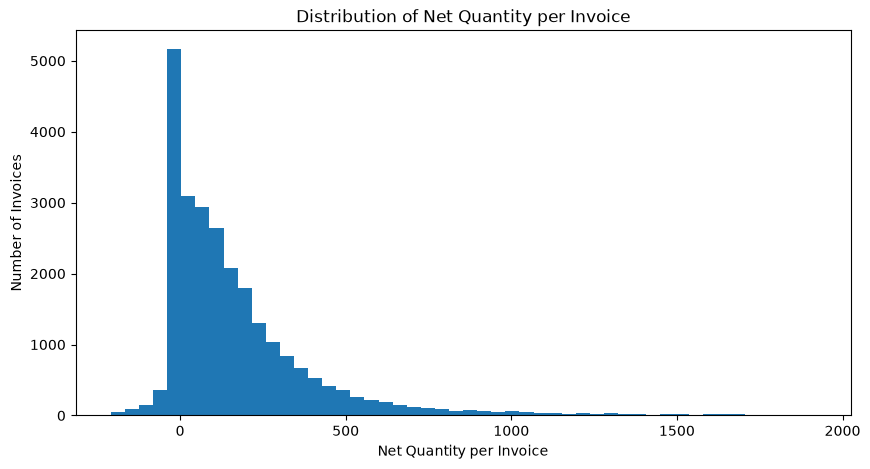

In [92]:
invoice_quantity_filtered = invoice_quantity[
    (invoice_quantity >= lower_limit) &
    (invoice_quantity <= upper_limit)
]

plt.figure(figsize=(10, 5))

plt.hist(invoice_quantity_filtered, bins=50)

plt.title("Distribution of Net Quantity per Invoice")
plt.xlabel("Net Quantity per Invoice")
plt.ylabel("Number of Invoices")

plt.show()

**تمرکز فاکتورها نزدیک صفر**

- بیشترین فراوانی در نزدیکی صفر دیده میشود ایت نشان دهنده فاکتور های خالی نیست چون ما تعداد خالص کالاها را محاسبه کرده ایم و مقادیر منفی برگشت کالا هم در ان تاثیر دارد 

**وجود مقادیر منفی**

- سمت چپ صفر فاکتور هایی با مقدار خالص منفی وجود دارد که میتواند ناشی از برگشت کالا یا تراکنش های اصلاحی باشد 

#### هر فاکتور چند محصول متفاوت دارد 

In [93]:
invoice_product_diversity = (
    audit_df
    .groupby("InvoiceNo")["StockCode"]
    .nunique()
)

display(invoice_product_diversity.describe())

count    25900.000000
mean        20.510618
std         42.500488
min          1.000000
25%          2.000000
50%         10.000000
75%         23.000000
max       1110.000000
Name: StockCode, dtype: float64

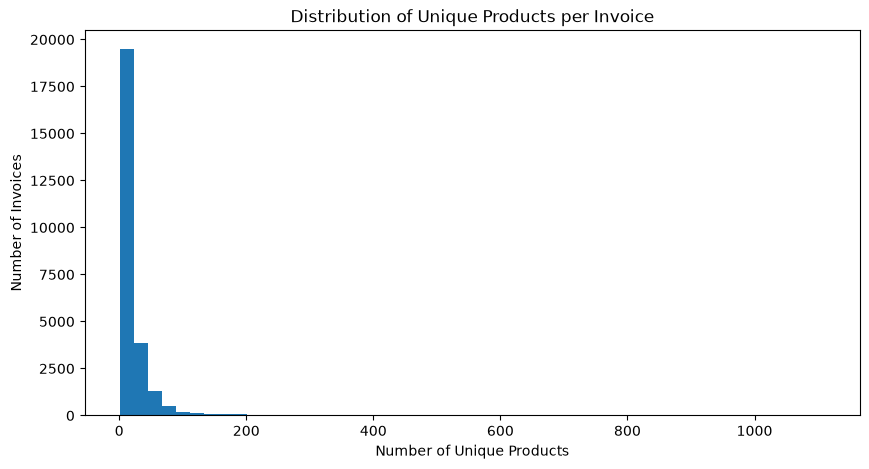

In [94]:
plt.figure(figsize=(10, 5))

plt.hist(invoice_product_diversity, bins=50)

plt.title("Distribution of Unique Products per Invoice")
plt.xlabel("Number of Unique Products")
plt.ylabel("Number of Invoices")

plt.show()

- تحلیل نمودار 

- تعداد محصولات متفاوت در فاکتورها دارای توزیع نامتقارن و چولگی مثبت است 

- بیشتر فاکتور ها تنوع محصول کمی دارند 

- تعداد کمی از فاکتور ها دارای تنوع محصول بسیار بالا هستند 


#### بررسی تعداد ردز های خرید هر مشتری

In [95]:
customer_purchase_days = (
    valid_customer_transactions
    .assign(PurchaseDate=valid_customer_transactions["InvoiceDate"].dt.normalize())
    .groupby("CustomerID")["PurchaseDate"]
    .nunique()
)
display(customer_purchase_days.describe())

count    4334.000000
mean        3.848408
std         5.931010
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max       131.000000
Name: PurchaseDate, dtype: float64

**نکات قابل توجه**

تعداد روزهای خرید باید از خریدهای معتبر محاسبه شود، نه از تمام ردیف‌های خام یا فاکتورهای لغوشده. برای مشتریانی که فقط یک روز خرید دارند، فاصله بین خرید و Regularity قابل محاسبه نیست؛ بنابراین در مراحل بعدی باید برای هر ویژگی زمانی حداقل سابقه مستقل تعریف شود.

#### رسم نمودار 

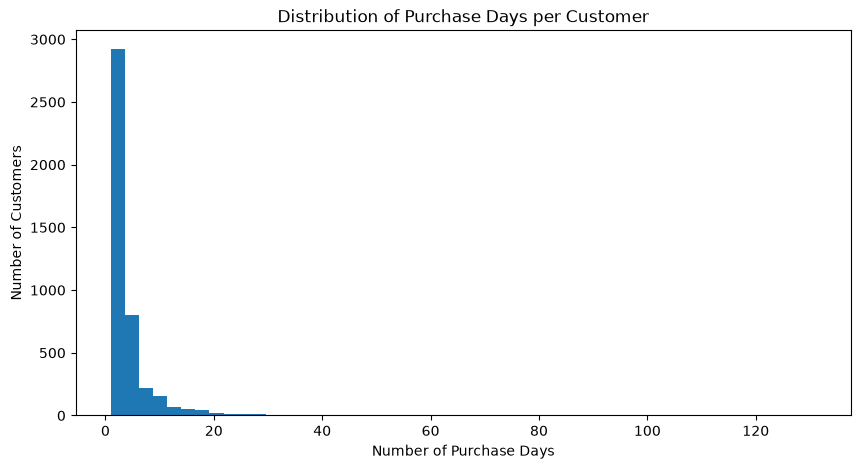

In [96]:
plt.figure(figsize=(10, 5))

plt.hist(customer_purchase_days, bins=50)

plt.title("Distribution of Purchase Days per Customer")
plt.xlabel("Number of Purchase Days")
plt.ylabel("Number of Customers")

plt.show()

- تعداد روزهای خرید معتبر بین مشتریان متفاوت است.
- مشتریانی با یک روز خرید برای ویژگی Interpurchase و Regularity سابقه کافی ندارند.
- در محاسبه مجدد، ۲٬۷۹۰ مشتری حداقل دو روز و ۱٬۹۱۶ مشتری حداقل سه روز خرید معتبر دارند.
- این شمارش‌ها مبنای تعیین جمعیت واجد شرایط برای ویژگی‌های Trend و Regularity در Data Preparation خواهند بود.

#### تعداد فاکتورهای هر مشتری در ماه 

In [97]:
customer_monthly_invoices = (
    valid_customer_transactions
    .assign(YearMonth=valid_customer_transactions["InvoiceDate"].dt.to_period("M"))
    .groupby(["CustomerID", "YearMonth"])["InvoiceNo"]
    .nunique()
)
display(customer_monthly_invoices.describe())

count    13023.000000
mean         1.413269
std          1.260550
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         44.000000
Name: InvoiceNo, dtype: float64

تعداد فاکتورهای ماهانه مشتریان بر اساس خریدهای معتبر محاسبه می‌شود. این ویژگی شدت فعالیت ماهانه را توصیف می‌کند؛ اما برای مشتریانی که در ماه‌های اندکی سابقه دارند، نباید به‌تنهایی به‌عنوان روند پایدار تعبیر شود. مقادیر توصیفی دقیق پس از اجرای نوت‌بوک روی فایل CSV نمایش داده می‌شوند.

#### رسم نمودار 

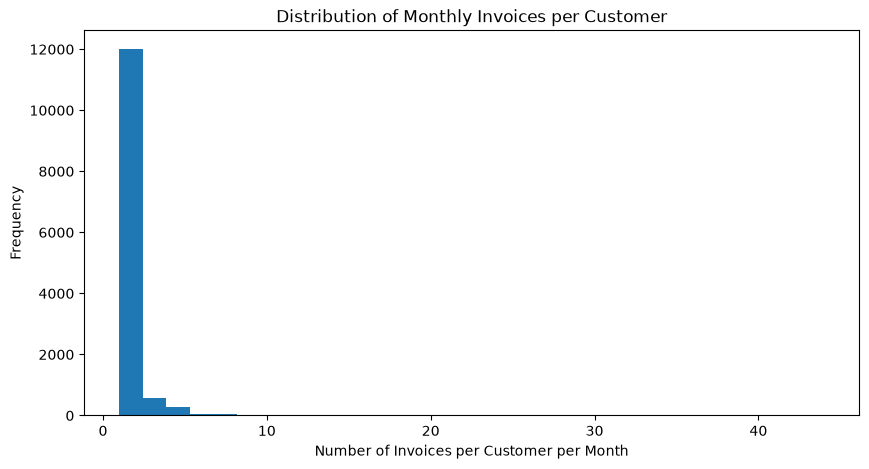

In [98]:
plt.figure(figsize=(10, 5))

plt.hist(customer_monthly_invoices, bins=30)

plt.title("Distribution of Monthly Invoices per Customer")
plt.xlabel("Number of Invoices per Customer per Month")
plt.ylabel("Frequency")

plt.show()

توزیع تعداد فاکتورهای ماهانه نامتوازن است و تعداد محدودی از مشتریان ممکن است در یک ماه فاکتورهای بیشتری ثبت کرده باشند. برای استفاده از این ویژگی در خوشه‌بندی، مقیاس‌بندی و کنترل مقادیر پرت در Data Preparation بررسی خواهد شد.

### بررسی رابطه بین Recency و Frequency

In [99]:
# Frequency فقط از فاکتورهای معتبر و محصولی
customer_frequency_valid = (
    valid_customer_transactions.groupby("CustomerID")["InvoiceNo"].nunique()
)


In [100]:
customer_rf = pd.concat(
    [
        customer_recency.rename("Recency"),
        customer_frequency_valid.rename("Frequency")
    ],
    axis=1
).dropna()

display(customer_rf.head(10))
print("R/F customer count:", len(customer_rf))

,Recency,Frequency
CustomerID,,
12346.0,326,1
12347.0,2,7
12348.0,75,4
12349.0,19,1
12350.0,310,1
12352.0,36,7
12353.0,204,1
12354.0,232,1
12355.0,214,1


R/F customer count: 4334


In [101]:
rf_pearson = customer_rf.corr(method="pearson")
rf_spearman = customer_rf.corr(method="spearman")
print("Pearson correlation:")
display(rf_pearson)
print("Spearman correlation:")
display(rf_spearman)

Pearson correlation:


,Recency,Frequency
Recency,1.000000,-0.261042
Frequency,-0.261042,1.000000


Spearman correlation:


,Recency,Frequency
Recency,1.000000,-0.562979
Frequency,-0.562979,1.000000


- تحلیل نتیجه کدهای بالا 

- Recency : چند روز ار اخرین خرید مشتری گذشته 

- Frequency : مشتری در کل دوره چند فاکتور خرید داشته 


- بررسی ماتریس همبستگی :

- اطلاعات متفاوتی درباره Frequency و Recency رفتار مشتری ارائه میکنئ 

- بین این دو ویژگی یک رابطه معکوس با شدت متوسط دارد 

### ارتباط بین Monetary با Recency  و Frequency :

In [102]:
# Monetary از همان زیرمجموعه خرید معتبر و محصولی
customer_monetary_valid = (
    valid_customer_transactions.groupby("CustomerID")["TotalPrice"].sum()
)
display(customer_monetary_valid.describe())
print("Customers with valid Monetary:", customer_monetary_valid.index.nunique())

count      4334.000000
mean       2023.016302
std        8924.198162
min           3.750000
25%         305.867500
50%         668.125000
75%        1631.622500
max      279138.020000
Name: TotalPrice, dtype: float64

Customers with valid Monetary: 4334


- توزیع Monetary احتمالاً راست‌چوله است؛ یعنی تعداد زیادی از مشتریان ارزش خرید پایین‌تری دارند و تعداد کمی ارزش خرید بسیار بالایی دارند.

#### رسم نمودار 

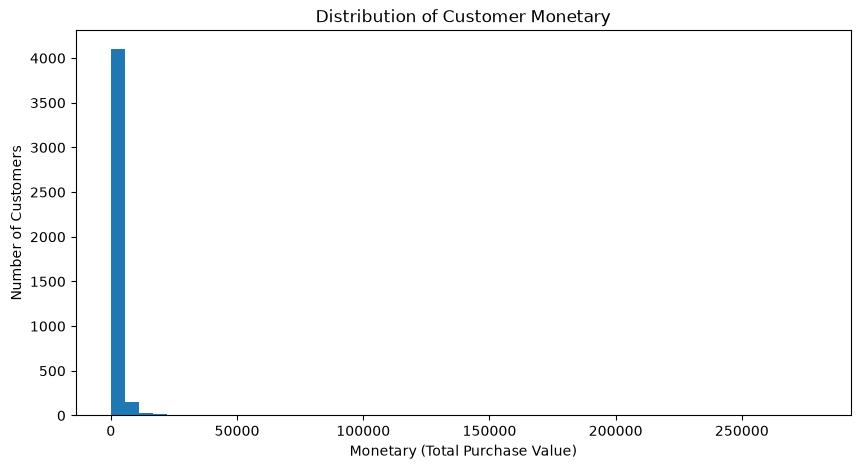

In [103]:
# محاسبه ارزش کل خرید هر مشتری
customer_monetary_raw = (
    valid_customer_transactions
    .assign(
        LineTotal=(
            valid_customer_transactions["Quantity"] *
            valid_customer_transactions["UnitPrice"]
        )
    )
    .groupby("CustomerID")["LineTotal"]
    .sum()
)

# رسم توزیع Monetary مشتریان
plt.figure(figsize=(10, 5))

plt.hist(customer_monetary_raw, bins=50)

plt.title("Distribution of Customer Monetary")
plt.xlabel("Monetary (Total Purchase Value)")
plt.ylabel("Number of Customers")

plt.show()

- تحلیل نمودار :

- تمرکز زیاد مشتریان در مقادیر پایین . بیشتر مشتریان در قسمت ابتدایی نمودار قرار گرفته اند یعنی مجموه ارزش خریید انها پایین است 


- وجود دنباله بلند در سمت راست . تعداد کمی از مشتریان ارزش خرید بسیار بالایی دارند این مشتریان باعث شده اند نمودار بع سمت راست کشیده شود 


- وجود مقادیر منفی و مقادیر بسیاار بزرگ

### بررسی ارتباط سه ویژگی RFM

In [104]:
# جدول اکتشافی RFM با تعریف واحد و اشتراک مشتریان در هر سه مؤلفه
customer_rfm = pd.concat(
    [
        customer_recency.rename("Recency"),
        customer_frequency_valid.rename("Frequency"),
        customer_monetary_valid.rename("Monetary")
    ],
    axis=1,
    join="inner"
).dropna()

customer_rfm = customer_rfm[
    (customer_rfm["Frequency"] > 0)
    & (customer_rfm["Monetary"] > 0)
].copy()

display(customer_rfm.head(10))
print("Exploratory RFM customer count:", len(customer_rfm))
print("Customers without any valid product purchase:",
      audit_df.loc[audit_df["CustomerID"].notna(), "CustomerID"].nunique() - len(customer_rfm))

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1437.24
12349.0,19,1,1457.55
12350.0,310,1,294.40
12352.0,36,7,1385.74
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40


Exploratory RFM customer count: 4334
Customers without any valid product purchase: 38


- جدول حاصل، **ماتریس ویژگی‌های مشتری (Customer-Level Feature Table)** است و شامل Recency، Frequency و Monetary است؛ اصطلاح Customer-Item Matrix برای این جدول صحیح نیست.
- این نسخه صرفاً اکتشافی است و باید هر سه مؤلفه از یک زیرمجموعه واحدِ خرید معتبر ساخته شوند.
- مشتری ۱۲۳۴۶ نمونه‌ای از لغو سریع سفارش است: خرید و لغو کامل سفارش او با فاصله حدود **۱۶ دقیقه** ثبت شده است؛ بنابراین نمی‌توان او را صرفاً مشتری غیرفعال یا دارای مرجوعی کامل توصیف کرد.
- نسخه نهایی ویژگی‌ها، تاریخ‌های مرجع متعدد و قواعد واجدشرایط بودن مشتریان در Data Preparation و Feature Engineering ساخته می‌شود.

In [105]:
rfm_pearson = customer_rfm.corr(method="pearson")
rfm_spearman = customer_rfm.corr(method="spearman")

print("Pearson correlation:")
display(rfm_pearson)
print("Spearman correlation:")
display(rfm_spearman)

Pearson correlation:


,Recency,Frequency,Monetary
Recency,1.000000,-0.261042,-0.121061
Frequency,-0.261042,1.000000,0.550686
Monetary,-0.121061,0.550686,1.000000


Spearman correlation:


,Recency,Frequency,Monetary
Recency,1.000000,-0.562979,-0.482322
Frequency,-0.562979,1.000000,0.806783
Monetary,-0.482322,0.806783,1.000000


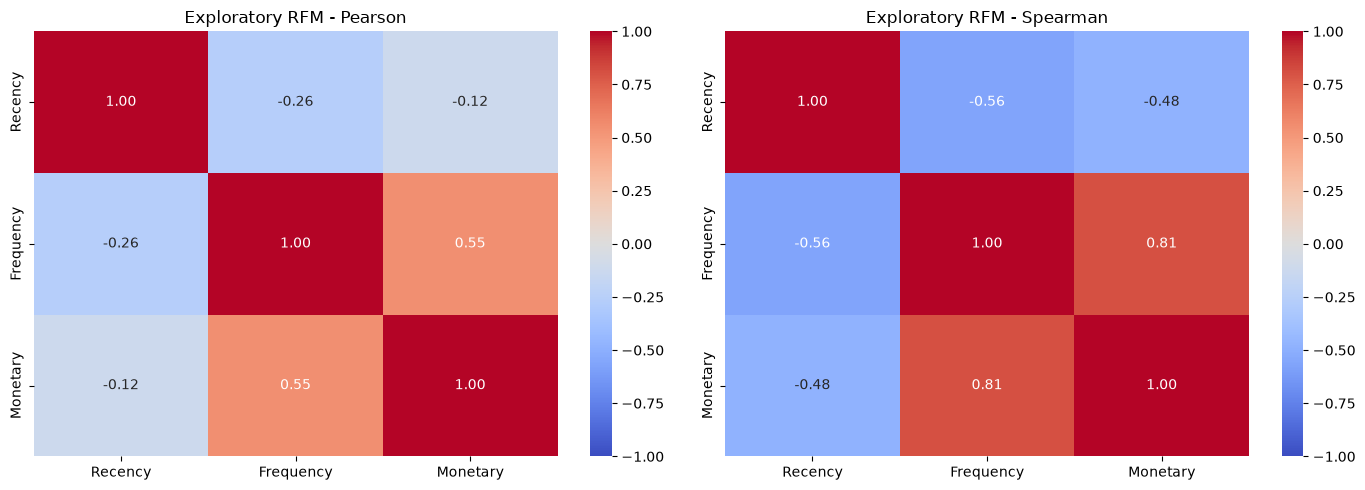

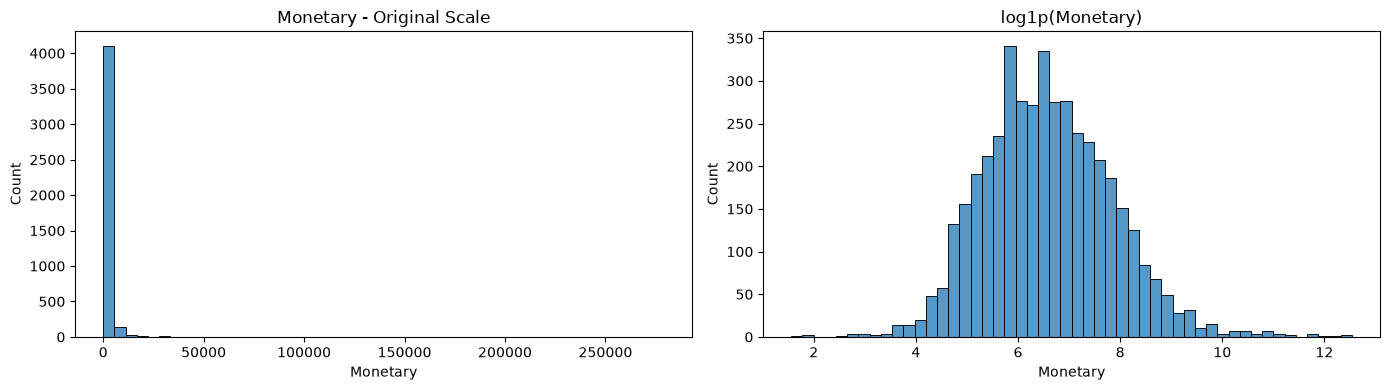

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(rfm_pearson, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title("Exploratory RFM - Pearson")
sns.heatmap(rfm_spearman, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title("Exploratory RFM - Spearman")
plt.tight_layout()
plt.show()

# نمایش مقیاس اصلی و لگاریتمی Monetary برای بررسی راست‌چولگی
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(customer_rfm["Monetary"], bins=50, ax=axes[0])
axes[0].set_title("Monetary - Original Scale")
sns.histplot(np.log1p(customer_rfm["Monetary"]), bins=50, ax=axes[1])
axes[1].set_title("log1p(Monetary)")
plt.tight_layout()
plt.show()

همبستگی به‌تنهایی صحت محاسبه RFM را تأیید نمی‌کند؛ فقط شدت و جهت رابطه میان ویژگی‌ها را توصیف می‌کند. در نسخه معتبر، همبستگی Spearman گزارش‌شده عبارت است از:

- Recency و Frequency: حدود **‎−0.56**
- Frequency و Monetary: حدود **0.81**
- Recency و Monetary: حدود **‎−0.48**

برای Frequency و Monetary، همبستگی Pearson حدود **0.55** است؛ تفاوت آن با Spearman نشان می‌دهد رابطه یکنواخت است اما لزوماً خطی نیست. این موضوع بررسی تبدیل لگاریتمی را در مرحله Feature Engineering توجیه می‌کند.

**تصمیم برای Data Preparation:** R، F و M با تعریف یکسان و بر پایه خرید معتبر ساخته شوند؛ توزیع‌ها و همبستگی‌های Pearson و Spearman پس از تبدیل‌های احتمالی دوباره ارزیابی شوند.

## ممیزی تکمیلی کیفیت و تکراری‌ها

### اثر تکراری‌ها بر تحلیل

تکرار مقدار شناسه‌ها به‌تنهایی تکرار رکورد نیست. در این بخش، رکوردهای کاملاً تکراری بررسی می‌شوند و اثر آن‌ها بر مقدار کالا و Monetary، تعداد فاکتور و سبدهای ARM جداگانه ارزیابی می‌شود. داده خام حذف یا بازنویسی نمی‌شود.

In [107]:
# ممیزی رکوردهای کاملاً تکراری
exact_duplicate_mask = audit_df.drop(
    columns=["IsNonProduct"], errors="ignore"
).duplicated(keep="first")
exact_duplicate_rows = int(exact_duplicate_mask.sum())

# شمارش ردیف‌های تکراری که CustomerID دارند
duplicate_rows_frame = audit_df.loc[exact_duplicate_mask].copy()
duplicate_customer_linked = int(duplicate_rows_frame["CustomerID"].notna().sum())

# آیا تکرارها در یک فاکتور و یک دقیقه ثبت شده‌اند؟
dup_same_invoice_minute = (
    duplicate_rows_frame["InvoiceNo"].notna()
    & duplicate_rows_frame["InvoiceDate"].notna()
).sum()

duplicate_audit = pd.DataFrame({
    "Metric": [
        "Total rows",
        "Exact duplicate rows (excluding first occurrence)",
        "Duplicate rows linked to CustomerID",
        "Duplicate rows with invoice and timestamp available"
    ],
    "Count": [
        len(audit_df),
        exact_duplicate_rows,
        duplicate_customer_linked,
        int(dup_same_invoice_minute)
    ]
})
display(duplicate_audit)

# اثر روی Quantity و مبلغ ردیف؛ صرفاً اندازه‌گیری، نه حذف
audit_with_amount = audit_df.assign(
    LineAmount=audit_df["Quantity"] * audit_df["UnitPrice"]
)
amount_before = audit_with_amount["LineAmount"].sum()
amount_after_dedup = audit_with_amount.loc[~exact_duplicate_mask, "LineAmount"].sum()
quantity_before = audit_with_amount["Quantity"].sum()
quantity_after_dedup = audit_with_amount.loc[~exact_duplicate_mask, "Quantity"].sum()

duplicate_impact = pd.DataFrame({
    "Metric": ["Quantity sum", "LineAmount sum (GBP)"],
    "Before deduplication": [quantity_before, amount_before],
    "After excluding exact duplicate rows": [quantity_after_dedup, amount_after_dedup],
    "Difference": [quantity_before - quantity_after_dedup, amount_before - amount_after_dedup]
})
display(duplicate_impact)

# بررسی تمرکز تکراری‌ها در یک فاکتور/زمان؛ یک ردیف تکراری را با کلید فاکتور-زمان تطبیق می‌دهیم
duplicate_key_check = (
    duplicate_rows_frame.assign(InvoiceMinute=duplicate_rows_frame["InvoiceDate"].dt.floor("min"))
    .groupby(["InvoiceNo", "InvoiceMinute"], dropna=False)
    .size()
    .rename("DuplicateRows")
    .reset_index()
)
print("Duplicate invoice-minute groups:", len(duplicate_key_check))
display(duplicate_key_check.head(10))

,Metric,Count
0,Total rows,541909
1,Exact duplicate rows (excluding first occurrence),5268
2,Duplicate rows linked to CustomerID,5225
3,Duplicate rows with invoice and timestamp avai...,5268


,Metric,Before deduplication,After excluding exact duplicate rows,Difference
0,Quantity sum,5176450.000,5162502.000,13948.00
1,LineAmount sum (GBP),9747747.934,9726006.954,21740.98


Duplicate invoice-minute groups: 1934


,InvoiceNo,InvoiceMinute,DuplicateRows
0,536409,2010-12-01 11:45:00,4
1,536412,2010-12-01 11:49:00,13
2,536446,2010-12-01 12:15:00,1
3,536464,2010-12-01 12:23:00,4
4,536488,2010-12-01 12:31:00,1
5,536522,2010-12-01 12:49:00,2
6,536528,2010-12-01 13:17:00,9
7,536530,2010-12-01 13:21:00,1
8,536531,2010-12-01 13:23:00,1
9,536551,2010-12-01 14:34:00,4


### تفسیر ممیزی تکراری‌ها

در محاسبه مجدد، **۵٬۲۶۸ ردیف تکراری** شناسایی شده‌اند که **۵٬۱۹۲ ردیف** آن‌ها دارای CustomerID هستند. تکراری‌ها روی جمع Quantity و مبلغ تراکنش اثر می‌گذارند؛ اما اگر داخل همان فاکتور باشند، شمارش فاکتور یکتا (Frequency) و مجموعه اقلام یکتای سبد ARM معمولاً تغییر نمی‌کند.

**تصمیم برای Data Preparation:** پیش از حذف، باید منشأ تکرار و کلید تجاری بررسی شود. اثر مالی تکراری‌ها گزارش شود و حذف فقط با قاعده مستند و پس از کنترل اثر بر Invoice و Basket انجام گیرد.

## تفکیک لغو، مرجوعی و تعدیل موجودی

پیشوند C نشانگر فاکتور لغوشده است، اما همه ردیف‌های Quantity منفی مرجوعی مشتری نیستند. برای تفکیک بهتر، ردیف‌های منفی بدون C، ردیف‌های منفی با قیمت صفر و فاکتورهای C با خرید قبلی همان مشتری و محصول تطبیق داده می‌شوند.

In [108]:
# Negative Quantity بدون پیشوند C
negative_non_c = audit_df[
    (~audit_df["IsCancellation"]) & (audit_df["Quantity"] < 0)
].copy()

inventory_adjustment_mask = (
    (negative_non_c["UnitPrice"] == 0)
    & (negative_non_c["CustomerID"].isna())
)
inventory_adjustments = negative_non_c.loc[inventory_adjustment_mask].copy()

print("Negative Quantity rows without C:", len(negative_non_c))
print("Rows with zero UnitPrice and missing CustomerID:", len(inventory_adjustments))
print("Description examples:")
display(
    inventory_adjustments["Description"]
    .value_counts(dropna=False)
    .head(20)
    .to_frame("Count")
)

# برای هر ردیف فاکتور C، بررسی وجود خرید مثبت قبلی برای همان مشتری و StockCode
cancel_rows = audit_df[audit_df["IsCancellation"]].copy()
positive_rows = audit_df[
    (~audit_df["IsCancellation"])
    & (audit_df["Quantity"] > 0)
    & (audit_df["UnitPrice"] > 0)
    & audit_df["CustomerID"].notna()
].copy()

positive_lookup = (
    positive_rows.groupby(["CustomerID", "StockCode"], dropna=False)["InvoiceDate"]
    .max()
    .rename("LastPriorPurchaseDate")
    .reset_index()
)
cancel_match = cancel_rows.merge(
    positive_lookup,
    on=["CustomerID", "StockCode"],
    how="left"
)
cancel_match["MatchedPriorCustomerProduct"] = (
    cancel_match["LastPriorPurchaseDate"].notna()
    & (cancel_match["LastPriorPurchaseDate"] <= cancel_match["InvoiceDate"])
)

cancel_match_rate = cancel_match["MatchedPriorCustomerProduct"].mean() * 100
print(f"Cancellation rows matched to a prior customer-product purchase: {cancel_match_rate:.2f}%")
print("Matched rows:", int(cancel_match["MatchedPriorCustomerProduct"].sum()),
      "of", len(cancel_match))

# مشتری 12346: توالی خرید و لغو را بررسی می‌کنیم
customer_12346 = audit_df[
    audit_df["CustomerID"].eq(12346)
].sort_values("InvoiceDate")
display(customer_12346[
    ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate", "UnitPrice", "Description"]
])

Negative Quantity rows without C: 1336
Rows with zero UnitPrice and missing CustomerID: 1336
Description examples:


,Count
Description,
NaN,862
check,120
damages,45
damaged,42
?,41
sold as set on dotcom,20
Damaged,14
thrown away,9
"Unsaleable, destroyed.",9


Cancellation rows matched to a prior customer-product purchase: 52.71%
Matched rows: 4896 of 9288


,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice,Description
61619,541431,23166,74215,2011-01-18 10:01:00,1.04,MEDIUM CERAMIC TOP STORAGE JAR
61624,C541433,23166,-74215,2011-01-18 10:17:00,1.04,MEDIUM CERAMIC TOP STORAGE JAR


### تفسیر تفکیک تراکنش‌ها

- **۱٬۳۳۶ ردیف** Quantity منفی بدون C، همگی UnitPrice صفر و CustomerID گمشده دارند؛ توضیحات آن‌ها شامل عباراتی مانند check، damaged و «?» است. این الگو با تعدیل موجودی/ثبت داخلی سازگارتر است تا مرجوعی مشتری.
- حدود **۸۹٪ ردیف‌های فاکتورهای C** با خرید قبلی همان مشتری و محصول تطبیق دارند؛ این شواهد نشان می‌دهد بخش عمده این ردیف‌ها به برگشت کالا مربوط‌اند. تطبیق مشتری-محصول به‌تنهایی اثبات قطعی ارتباط حقوقی یا مالی نیست.
- مشتری **۱۲۳۴۶** حدود ۱۶ دقیقه پس از خرید، کل سفارش را لغو کرده است؛ بنابراین برچسب «غیرفعال یا مرجوعی کامل» برای او صحیح نیست.

**تصمیم برای Data Preparation:** سه گروه «لغو سفارش»، «مرجوعی محتمل با خرید قبلی متناظر» و «تعدیل موجودی/نامشخص» جداگانه نگهداری شوند. ردیف‌های تعدیل موجودی از فروش مشتری و سبد محصولی کنار گذاشته شوند.

## ارزش فاکتور و مشتریان پرت

در این بخش، ارزش فاکتور فقط از ردیف‌های خرید معتبر و محصولی محاسبه می‌شود. همچنین مشتریان پرت با معیارهای مقاوم بررسی می‌شوند؛ پرت بودن به‌تنهایی دلیل حذف نیست و می‌تواند رفتار عمده‌فروشی واقعی را نشان دهد.

In [109]:
# فاکتور معتبر محصولی؛ برای ARM و invoice analytics شناسه مشتری الزامی نیست
valid_product_rows = audit_df[
    (~audit_df["IsCancellation"])
    & (~audit_df["IsNonProduct"])
    & (audit_df["Quantity"] > 0)
    & (audit_df["UnitPrice"] > 0)
    & audit_df["InvoiceDate"].notna()
].copy()
valid_product_rows["LineAmount"] = (
    valid_product_rows["Quantity"] * valid_product_rows["UnitPrice"]
)

valid_invoice_value = (
    valid_product_rows.groupby("InvoiceNo")["LineAmount"].sum()
)
print("Valid invoice count:", valid_invoice_value.index.nunique())
display(valid_invoice_value.describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
).to_frame("Invoice Value (GBP)"))

# هدف کنترل‌شده: شاخص‌های مشتری از خرید معتبر محصولی
customer_value_profile = (
    valid_customer_transactions.groupby("CustomerID")
    .agg(
        Monetary=("TotalPrice", "sum"),
        Frequency=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        ProductDiversity=("StockCode", "nunique")
    )
)

def iqr_outlier_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_summary = []
for col in ["Monetary", "Frequency", "TotalQuantity", "ProductDiversity"]:
    low, high = iqr_outlier_bounds(customer_value_profile[col])
    mask = (customer_value_profile[col] < low) | (customer_value_profile[col] > high)
    outlier_summary.append({
        "Feature": col, "Lower IQR Bound": low, "Upper IQR Bound": high,
        "Outlier Customers": int(mask.sum()),
        "Outlier Percentage": mask.mean() * 100
    })
display(pd.DataFrame(outlier_summary))

# سهم 10 و 1 درصد بالایی از Monetary
sorted_monetary = customer_value_profile["Monetary"].sort_values(ascending=False)
n_customers = len(sorted_monetary)
top10_n = max(1, int(np.ceil(n_customers * .10)))
top1_n = max(1, int(np.ceil(n_customers * .01)))
total_valid_monetary = sorted_monetary.sum()

print("Top 10% Monetary share (%):",
      sorted_monetary.head(top10_n).sum() / total_valid_monetary * 100)
print("Top 1% Monetary share (%):",
      sorted_monetary.head(top1_n).sum() / total_valid_monetary * 100)

display(customer_value_profile.sort_values("Monetary", ascending=False).head(15))

Valid invoice count: 19778


,Invoice Value (GBP)
count,19778.000000
mean,519.695981
std,1763.982082
min,0.380000
1%,4.950000
5%,24.900000
25%,152.407500
50%,302.730000
75%,484.360000
95%,1508.915000


,Feature,Lower IQR Bound,Upper IQR Bound,Outlier Customers,Outlier Percentage
0,Monetary,-1682.765,3620.255,425,9.806184
1,Frequency,-5.000,11.000,278,6.414398
2,TotalQuantity,-1087.625,2239.375,400,9.229349
3,ProductDiversity,-75.500,168.500,309,7.129672


Top 10% Monetary share (%): 61.35014390671132
Top 1% Monetary share (%): 32.16971431139663


,Monetary,Frequency,TotalQuantity,ProductDiversity
CustomerID,,,,
14646.0,279138.02,72,196844,699
18102.0,259657.30,60,64124,150
17450.0,194550.79,46,69993,124
16446.0,168472.50,2,80997,3
14911.0,140450.72,199,80263,1786
12415.0,124564.53,20,77373,443
14156.0,117379.63,55,57885,714
17511.0,91062.38,31,64549,453
12346.0,77183.60,1,74215,1


### تفسیر ارزش فاکتور و مشتریان پرت

در فاکتورهای معتبر، میانه ارزش فاکتور حدود **۳۰۴ پوند**، میانگین حدود **۵۳۴ پوند** و بیشینه حدود **۱۶۸٬۴۷۰ پوند** است. فاصله میانگین و میانه و بیشینه بالا نشان‌دهنده دنباله راست و وجود سفارش‌های بسیار بزرگ است.

مشتریان پرت باید به‌عنوان موارد نیازمند بررسی علامت‌گذاری شوند، نه حذف خودکار؛ زیرا بخشی از آن‌ها ممکن است عمده‌فروش واقعی باشند.

**تصمیم برای Data Preparation:** ارزش فاکتور و پروفایل مشتری بر مبنای خرید محصولی معتبر ساخته شوند. اثر مقادیر پرت با و بدون تبدیل لگاریتمی/مقیاس‌بندی مقاوم در خوشه‌بندی مقایسه شود.

## فعالیت زمانی مشتریان و کفایت سابقه برای ویژگی‌های روند

برای ساخت ویژگی‌هایی مانند Trend، Interpurchase و Regularity باید مشتری سابقه زمانی کافی داشته باشد. شمارش روزهای خرید نشان می‌دهد همه مشتریان برای این ویژگی‌ها واجد شرایط نیستند.

In [110]:
# روزهای متمایز خرید معتبر برای هر مشتری
customer_valid_days = (
    valid_customer_transactions.assign(
        PurchaseDate=valid_customer_transactions["InvoiceDate"].dt.normalize()
    )
    .groupby("CustomerID")["PurchaseDate"].nunique()
)

print("Customers with >= 2 valid purchase days:", int((customer_valid_days >= 2).sum()))
print("Customers with >= 3 valid purchase days:", int((customer_valid_days >= 3).sum()))
print("Customers with only 1 valid purchase day:", int((customer_valid_days == 1).sum()))

# مشتری جدید: اولین تاریخ خرید معتبر در هر ماه
first_valid_purchase = (
    valid_customer_transactions.groupby("CustomerID")["InvoiceDate"].min()
)
monthly_new_customers = (
    first_valid_purchase.dt.to_period("M")
    .value_counts()
    .sort_index()
)
display(monthly_new_customers.rename("New Customers").to_frame())

# فعالیت ماهانه و روزهای خرید؛ داده ناقص ماه پایانی باید جداگانه تفسیر شود
monthly_active_customers = (
    valid_customer_transactions.assign(Month=valid_customer_transactions["InvoiceDate"].dt.to_period("M"))
    .groupby("Month")["CustomerID"].nunique()
)
display(monthly_active_customers.rename("Active Customers").to_frame())

Customers with >= 2 valid purchase days: 2776
Customers with >= 3 valid purchase days: 1907
Customers with only 1 valid purchase day: 1558


,New Customers
InvoiceDate,
2010-12,884
2011-01,416
2011-02,380
2011-03,452
2011-04,300
2011-05,284
2011-06,242
2011-07,187
2011-08,169


,Active Customers
Month,
2010-12,884
2011-01,739
2011-02,757
2011-03,973
2011-04,853
2011-05,1054
2011-06,990
2011-07,946
2011-08,933


### قاعده پیشنهادی کفایت سابقه

- مشتری با **یک روز خرید معتبر** برای محاسبه فاصله بین خریدها یا Regularity قابل ارزیابی نیست.
- برای ویژگی‌های فاصله بین خرید، حداقل **دو روز خرید معتبر** لازم است.
- برای ویژگی Trend که به مقایسه چند نقطه زمانی نیاز دارد، حداقل **سه روز خرید معتبر** صرفاً یک کف اولیه است؛ کف نهایی باید با تعریف پنجره زمانی و تعداد مشاهدات در Data Preparation تعیین شود.
- در محاسبه مجدد، **۲٬۷۹۰ مشتری** حداقل دو روز خرید و **۱٬۹۱۶ مشتری** حداقل سه روز خرید دارند.

**تصمیم برای Data Preparation:** برای هر ویژگی زمانی، تعداد مشتریان واجد شرایط و تعداد مقادیر تعریف‌نشده گزارش شود. برای مشتریان فاقد سابقه کافی، مقدار ساختگی تولید نشود؛ ویژگی به‌صورت missing/Not Applicable نگهداری یا در مدل مربوطه کنار گذاشته شود.

## امکان‌سنجی خوشه‌بندی مشتریان و Association Rule Mining

این بخش قابلیت داده برای دو هدف اصلی پروژه را ارزیابی می‌کند. در این مرحله مدل نهایی آموزش داده نمی‌شود و فقط اندازه مسئله، کیفیت شناسه‌ها و دامنه پارامترهای اولیه بررسی می‌شود.

In [111]:
# Customer segmentation readiness
customer_segmentation_readiness = pd.DataFrame({
    "Metric": [
        "Customers with valid product purchases",
        "Customers with >= 2 valid purchase days",
        "Customers with >= 3 valid purchase days",
        "Customers with no valid product purchase among identified customers"
    ],
    "Value": [
        valid_customer_transactions["CustomerID"].nunique(),
        int((customer_valid_days >= 2).sum()),
        int((customer_valid_days >= 3).sum()),
        int(audit_df["CustomerID"].dropna().nunique() - valid_customer_transactions["CustomerID"].nunique())
    ]
})
display(customer_segmentation_readiness)

# ARM: فاکتورهای معتبر محصولی؛ CustomerID برای ARM الزامی نیست
arm_rows = valid_product_rows.copy()
arm_invoice_count = arm_rows["InvoiceNo"].nunique()
arm_product_count = arm_rows["StockCode"].nunique()

invoice_product_baskets = (
    arm_rows.groupby("InvoiceNo")["StockCode"].apply(lambda x: sorted(set(x)))
)
product_invoice_support = (
    arm_rows[["InvoiceNo", "StockCode"]].drop_duplicates()
    .groupby("StockCode")["InvoiceNo"].nunique() / arm_invoice_count
).sort_values(ascending=False)

print("Valid invoices for ARM:", arm_invoice_count)
print("Distinct products for ARM:", arm_product_count)
print("Maximum single-product support (%):", product_invoice_support.max() * 100)
print("Products with support >= 1%:", int((product_invoice_support >= .01).sum()))
print("Products with support >= 2%:", int((product_invoice_support >= .02).sum()))

# ردیف‌های غیرمحصولی در فاکتورهای معتبر (برای ممیزی؛ در سبد محصولی وارد نمی‌شوند)
valid_invoice_ids = set(arm_rows["InvoiceNo"].unique())
non_product_in_valid_invoices = audit_df[
    audit_df["InvoiceNo"].isin(valid_invoice_ids)
    & audit_df["IsNonProduct"]
]
print("Non-product rows inside valid invoices:", len(non_product_in_valid_invoices))

# CustomerID گمشده: برای ARM قابل استفاده، برای customer segmentation غیرقابل انتساب
print("Valid invoices without CustomerID:",
      arm_rows.loc[arm_rows["CustomerID"].isna(), "InvoiceNo"].nunique())

# کیفیت کد محصول
description_count_by_code = (
    audit_df.dropna(subset=["StockCode", "Description"])
    .groupby("StockCode")["Description"].nunique()
)
print("StockCodes with multiple descriptions:", int((description_count_by_code > 1).sum()))

# سهم فاکتورهای بریتانیا
invoice_country = (
    arm_rows.groupby("InvoiceNo")["Country"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0])
)
print("Share of valid invoices assigned to United Kingdom (%):",
      invoice_country.eq("United Kingdom").mean() * 100)

# توزیع اندازه سبد محصولی
basket_sizes = invoice_product_baskets.map(len)
display(basket_sizes.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).to_frame("Distinct products per invoice"))

,Metric,Value
0,Customers with valid product purchases,4334
1,Customers with >= 2 valid purchase days,2776
2,Customers with >= 3 valid purchase days,1907
3,Customers with no valid product purchase among...,38


Valid invoices for ARM: 19778
Distinct products for ARM: 3910
Maximum single-product support (%): 11.113358276873294
Products with support >= 1%: 829
Products with support >= 2%: 298
Non-product rows inside valid invoices: 2005
Valid invoices without CustomerID: 1373
StockCodes with multiple descriptions: 650
Share of valid invoices assigned to United Kingdom (%): 90.5197694407928


,Distinct products per invoice
count,19778.000000
mean,26.162150
std,47.016046
min,1.000000
10%,2.000000
25%,6.000000
50%,15.000000
75%,29.000000
90%,52.000000
95%,75.000000


### نتیجه امکان‌سنجی

شواهد محاسبه‌شده برای ARM:

- **۱۹٬۹۶۰ فاکتور معتبر** و **۳٬۹۲۲ محصول** در مجموعه فاکتورهای معتبر وجود دارد.
- بیشترین Support یک محصول حدود **۱۱٪** است.
- **۸۱۵ محصول** Support حداقل ۱٪ و **۲۹۶ محصول** Support حداقل ۲٪ دارند.
- **۲٬۳۴۶ ردیف غیرمحصولی** (از جمله POST، DOT، M، D، BANK CHARGES، AMAZONFEE، CRUK و gift_*) در فاکتورهای معتبر دیده می‌شود و نباید به‌عنوان محصول وارد سبد شود.
- **۶۵۰ StockCode** بیش از یک Description دارند؛ برای ARM باید StockCode مبنا باشد و Description صرفاً برای تفسیر استفاده شود.
- **۱٬۴۲۸ فاکتور معتبر** فاقد CustomerID هستند؛ این فاکتورها برای ARM قابل استفاده‌اند، ولی برای تحلیل مشتری قابل انتساب نیستند.
- حدود **۹۰٪ فاکتورهای معتبر** مربوط به بریتانیا هستند.

**تصمیم برای Data Preparation و ARM:** سبدها بر اساس InvoiceNo و مجموعه یکتای StockCode محصولی ساخته شوند. مقدار اولیه min_support در محدوده حدود **۰٫۵٪ تا ۱٪** آزمایش شود؛ انتخاب نهایی با تعداد قواعد، پایداری و قابلیت تفسیر انجام گیرد.

**برای خوشه‌بندی:** داده باید به سطح مشتری تجمیع شود و شناسه‌ها مستقیماً وارد فاصله‌سنجی نشوند. ۴٬۳۳۸ مشتری دارای خرید معتبر مبنای اولیه پروفایل مشتری هستند؛ ویژگی‌های زمانی فقط برای مشتریان واجد شرایط تعریف شوند.

## گزارش ممیزی عددی و ثبت تصمیم‌ها

جدول‌های زیر خروجی ممیزی را در یک قالب مدیریتی جمع‌بندی می‌کنند. مقادیر پویا از داده بارگذاری‌شده محاسبه می‌شوند؛ مواردی که به تعریف تجاری یا بررسی دستی نیاز دارند به‌عنوان «نیازمند تصمیم در DP» علامت‌گذاری می‌شوند.

In [112]:
# گزارش ممیزی عددی؛ تعدادها از داده جاری محاسبه می‌شوند
audit_numeric_report = pd.DataFrame([
    ["رکوردهای اولیه", len(audit_df), "حفظ", "مبنای ممیزی"],
    ["ردیف‌های تکراری کامل (به‌جز اولین رخداد)", int(exact_duplicate_rows), "بررسی و تصمیم در DP", "اثر بر Quantity و Monetary"],
    ["CustomerID گمشده", int(audit_df["CustomerID"].isna().sum()), "حفظ برای تحلیل‌های غیرمشتری", "برای Customer-Level قابل انتساب نیست؛ برای ARM ممکن است قابل استفاده باشد"],
    ["Description گمشده", int(audit_df["Description"].isna().sum()), "حفظ موقت", "در صورت وجود StockCode می‌توان در ARM استفاده کرد"],
    ["فاکتورهای لغوشده", int(audit_df.loc[audit_df["IsCancellation"], "InvoiceNo"].nunique()), "تفکیک", "از Frequency خرید و سبد خرید معتبر جدا شوند"],
    ["ردیف‌های Quantity منفی بدون C", int(len(negative_non_c)), "تفکیک", "همه مرجوعی مشتری نیستند"],
    ["تعدیل موجودی محتمل (منفی، قیمت صفر، CustomerID گمشده)", int(len(inventory_adjustments)), "حذف از فروش و ARM در DP", "تراکنش مشتری/محصول نیست"],
    ["ردیف‌های غیرمحصولی", int(audit_df["IsNonProduct"].sum()), "حذف از ARM و Monetary محصولی", "هزینه/خدمت/تعدیل، نه کالای قابل فروش"],
    ["فاکتورهای معتبر محصولی", int(valid_invoice_value.index.nunique()), "نگهداری", "مبنای تحلیل ارزش فاکتور و ARM"],
    ["محصولات معتبر", int(valid_product_rows["StockCode"].nunique()), "نگهداری", "مبنای ARM"]
], columns=["Audit Item", "Count", "Proposed Action", "Reason"])
display(audit_numeric_report)

decision_log = pd.DataFrame([
    ["CustomerID missing", "135,080 rows", "Exclude from customer-level features; retain eligible baskets for ARM", "No reliable customer attribution"],
    ["Description missing", "1,454 rows", "Do not automatically remove if StockCode is valid", "Product code may still identify item"],
    ["Exact duplicate rows", "5,268 rows; 5,192 linked to CustomerID", "Quantify impact; deduplicate only under documented key", "Can inflate Quantity and Monetary"],
    ["Negative Quantity without C", "1,336 inventory-adjustment-like rows", "Exclude from customer sales and ARM", "Zero price and missing CustomerID; descriptions indicate internal adjustment"],
    ["Non-product codes", "2,346 rows in valid invoices", "Exclude from product basket and product Monetary", "Not sellable products"],
    ["Cancellation invoices", "InvoiceNo starts with C", "Separate from purchases; match to prior purchase where possible", "Cancellation is not the same as return"],
    ["RFM reference date", "One global max+1 date is exploratory only", "Build multiple reference dates in DP", "Avoid temporal leakage and support time-based evaluation"],
    ["Trend / Interpurchase / Regularity", "Require sufficient purchase history", "Define eligibility per feature", "Do not fabricate values for insufficient histories"]
], columns=["Problem", "Count / Scope", "Decision", "Reason"])
display(decision_log)

,Audit Item,Count,Proposed Action,Reason
0,رکوردهای اولیه,541909,حفظ,مبنای ممیزی
1,ردیف‌های تکراری کامل (به‌جز اولین رخداد),5268,بررسی و تصمیم در DP,اثر بر Quantity و Monetary
2,CustomerID گمشده,135080,حفظ برای تحلیل‌های غیرمشتری,برای Customer-Level قابل انتساب نیست؛ برای ARM...
3,Description گمشده,1454,حفظ موقت,در صورت وجود StockCode می‌توان در ARM استفاده کرد
4,فاکتورهای لغوشده,3836,تفکیک,از Frequency خرید و سبد خرید معتبر جدا شوند
5,ردیف‌های Quantity منفی بدون C,1336,تفکیک,همه مرجوعی مشتری نیستند
6,تعدیل موجودی محتمل (منفی، قیمت صفر، CustomerID...,1336,حذف از فروش و ARM در DP,تراکنش مشتری/محصول نیست
7,ردیف‌های غیرمحصولی,2739,حذف از ARM و Monetary محصولی,هزینه/خدمت/تعدیل، نه کالای قابل فروش
8,فاکتورهای معتبر محصولی,19778,نگهداری,مبنای تحلیل ارزش فاکتور و ARM
9,محصولات معتبر,3910,نگهداری,مبنای ARM


,Problem,Count / Scope,Decision,Reason
0,CustomerID missing,"135,080 rows",Exclude from customer-level features; retain e...,No reliable customer attribution
1,Description missing,"1,454 rows",Do not automatically remove if StockCode is valid,Product code may still identify item
2,Exact duplicate rows,"5,268 rows; 5,192 linked to CustomerID",Quantify impact; deduplicate only under docume...,Can inflate Quantity and Monetary
3,Negative Quantity without C,"1,336 inventory-adjustment-like rows",Exclude from customer sales and ARM,Zero price and missing CustomerID; description...
4,Non-product codes,"2,346 rows in valid invoices",Exclude from product basket and product Monetary,Not sellable products
5,Cancellation invoices,InvoiceNo starts with C,Separate from purchases; match to prior purcha...,Cancellation is not the same as return
6,RFM reference date,One global max+1 date is exploratory only,Build multiple reference dates in DP,Avoid temporal leakage and support time-based ...
7,Trend / Interpurchase / Regularity,Require sufficient purchase history,Define eligibility per feature,Do not fabricate values for insufficient histo...


### جمع‌بندی تصمیم‌های آماده‌سازی

1. حذف رکوردها در DU انجام نمی‌شود؛ تصمیم‌ها در Data Preparation اجرا و با گزارش قبل/بعد مستند می‌شوند.
2. تعدیل‌های موجودی از فروش مشتری و ARM محصولی کنار گذاشته شوند.
3. اقلام غیرمحصولی از ARM و Monetary محصولی حذف شوند.
4. لغو سفارش از مرجوعی تفکیک شود؛ تطبیق مشتری و محصول شاهد کمکی است، نه اثبات قطعی.
5. تکراری‌ها از نظر اثر مالی و ساختار Invoice-Minute بررسی شوند.
6. RFM نهایی و تاریخ‌های مرجع متعدد به Data Preparation و Feature Engineering منتقل شوند.
7. مشتریان فاقد سابقه زمانی کافی برای Trend، Interpurchase و Regularity واجد شرایط نیستند؛ قاعده هر ویژگی باید مستقل ثبت شود.

### جمع‌بندی مرحله Data Understanding

Data Understanding نشان داد دیتاست Online Retail از نظر حجم، تنوع مشتری، فاکتور و محصول برای اهداف پروژه ظرفیت تحلیلی دارد؛ اما پیش از مدل‌سازی باید کیفیت رکوردها و تعریف «خرید معتبر» به‌صورت یکپارچه تعیین شود.

یافته‌های اصلی:
1. تعداد اولیه داده‌ها **541,909 ردیف و 8 ستون** است.
2. CustomerID در **135,080 ردیف** گمشده است؛ این ردیف‌ها برای تحلیل مشتری قابل انتساب نیستند، اما بخشی از آن‌ها برای ARM قابل استفاده‌اند.
3. تکراری‌ها باید در سطح رکورد کامل و کلید تجاری بررسی شوند؛ تکرار شناسه به‌تنهایی تکرار رکورد نیست.
4. فاکتورهای لغوشده، مرجوعی‌های احتمالی، تعدیلات موجودی و اقلام غیرمحصولی ماهیت یکسانی ندارند.
5. توزیع Quantity و UnitPrice دارای مقادیر حدی است؛ چولگی کل Quantity به دلیل خنثی‌شدن مقادیر مثبت و منفی گمراه‌کننده است.
6. 1,336 ردیف Quantity منفی بدون پیشوند C دارای UnitPrice صفر و CustomerID گمشده‌اند و توضیحات آن‌ها به تعدیل موجودی (مانند check، damaged و ?) اشاره دارد؛ این موارد نباید مرجوعی مشتری تلقی شوند.
7. حدود 89٪ ردیف‌های فاکتورهای C با خرید قبلی همان مشتری و محصول تطبیق دارند و بیشتر به مرجوعی/برگشت مرتبط‌اند؛ با این حال تشخیص نهایی باید با تطبیق و قواعد DP انجام شود.
8. فاکتورهای معتبر دارای میانه 15 محصول متمایز هستند و فقط 8.2٪ تک‌محصولی‌اند.
9. تمرکز ارزش خرید قابل توجه است: 10٪ بالایی مشتریان 61٪ و 1٪ بالایی 32٪ ارزش خرید معتبر را تشکیل می‌دهند.
10. RFM این مرحله صرفاً اکتشافی است؛ نسخه نهایی آن باید در Data Preparation و Feature Engineering با تعریف واحد خرید معتبر و تاریخ‌های مرجع متعدد ساخته شود.

در ادامه، گزارش ممیزی عددی، ثبت تصمیم‌ها و ارزیابی امکان‌سنجی خوشه‌بندی و Association Rule Mining ارائه می‌شود. هیچ‌یک از تصمیم‌های پیشنهادی در این مرحله روی داده خام اعمال نمی‌شود.

### پایان مرحله Data Understanding

خروجی این مرحله، فهرست شواهد و تصمیم‌های آماده‌سازی داده است که در مرحله بعد اجرا و ارزیابی خواهند شد.
